# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions, plot_date_range
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/commercial'

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # Hour frequency
USE_RESIDUAL = True  # If True, model the residuals (1-step differencing) instead of the original target.
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 2.0  # For commercial data

In [ ]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_com_hour_wfv', use_numpy=True)
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_3h', 'consumption_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 2 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 2 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
train[0][0]

array([[Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub1', 22.0, ..., 0.625, 0.6275000000000546, 0.621818181818195],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub3', 22.0, ..., 0.31666666666660603, 0.32416666666669397,
        0.3072727272727372],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub2', 22.0, ..., 0.004166666666662877, 0.0033333333333303017,
        0.003636363636370664],
       ...,
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub2', 21.0, ..., 0.004166666666662877, 0.004166666666662877,
        0.0033333333333397754],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub1', 21.0, ..., 0.5883333333334425, 0.6208333333330908,
        0.6091666666667758],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub3', 21.0, ..., 0.3674999999999879, 0.37333333333344854,
        0.3758333333333515]], shape=(2016, 9

In [7]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 2 splits
Validation data: 2 splits
First train split shape: X=(2016, 9), y=(2016,)
First valid split shape: X=(2016, 9), y=(2016,)

Memory usage:
Train: 0.46 MB
Valid: 0.21 MB
Test: 0.09 MB
Total: 0.77 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [8]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [ ]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.01 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.024620 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0652
	MAE: 0.0440
	MAPE: 469.6044%

Directional Metrics:
	Directional Accuracy: 53.3532%
	First-Diff Correlation: 0.0892

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1169
		Recall: 0.1250
		F1: 0.1208
	Drops:
		Precision: 0.2763
		Recall: 0.1579
		F1: 0.2010

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.024445 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0593
	MAE: 0.0386
	MAPE: 427.9335%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.0736

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0800
		Recall: 0.0833
		F1: 0.0816
	Drops:
		Precision: 0.3200
		Recall: 0.1509
		F1: 0.2051

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7200
		Recall: 0.7500
		F1: 0.7347
	Drops:
		Precision: 0.8000
		Recall: 0.3774
		F1: 0.5128
------------------------------------------------

#### Results

In [11]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0623 ± 0.0030
	MAE: 0.0413 ± 0.0027
	MAPE: 448.7690% ± 20.8354%

	Directional Metrics:
		Directional Accuracy: 52.0703% ± 1.2829%
		First-Diff Correlation: 0.0814 ± 0.0078

	Immediate Detection (delta=0):
		Spike Precision: 0.0984 ± 0.0184
		Spike Recall: 0.1042 ± 0.0208
		Spike F1: 0.1012 ± 0.0196
		Drop Precision: 0.2982 ± 0.0218
		Drop Recall: 0.1544 ± 0.0035
		Drop F1: 0.2030 ± 0.0021

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7366 ± 0.0166
		Spike Recall: 0.7778 ± 0.0278
		Spike F1: 0.7566 ± 0.0219
		Drop Precision: 0.7882 ± 0.0118
		Drop Recall: 0.4105 ± 0.0331
		Drop F1: 0.5387 ± 0.0259
Daily Metrics:
	RMSE: 0.0874 ± 0.0194
	MAE: 0.0618 ± 0.0114
	MAPE: 4.9706% ± 0.8126%

	Directional Metrics:
		Directional Accuracy: 98.1481% ± 1.8519%
		First-Diff Correlation: 0.9476 ± 0.0292

	Immediate Detection (delta=0):
		Spi

#### Validation plots

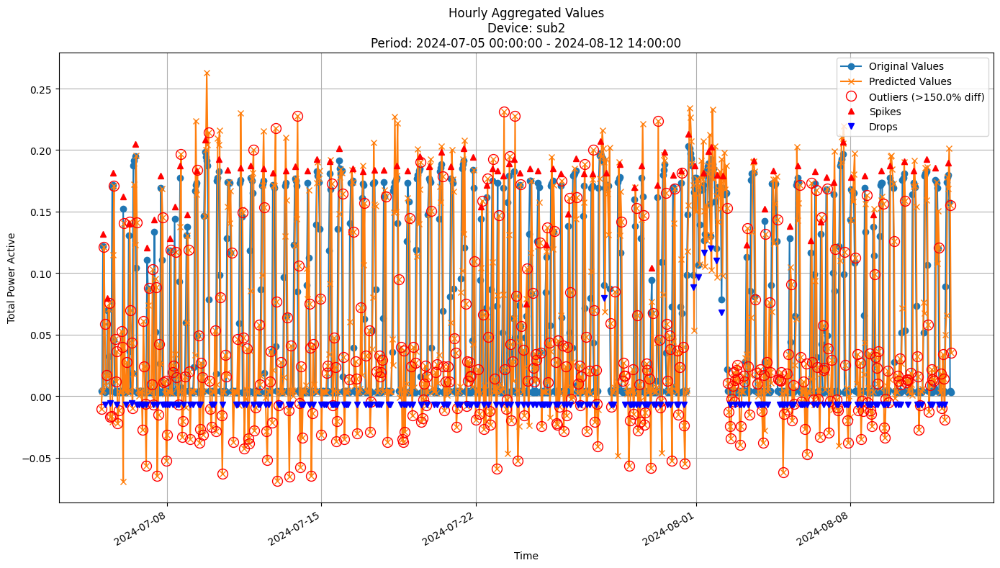


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0636
MAE: 0.0425
MAPE: 458.1416%

Directional Metrics:
Directional Accuracy: 52.5918%
First-Diff Correlation: 0.0855

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


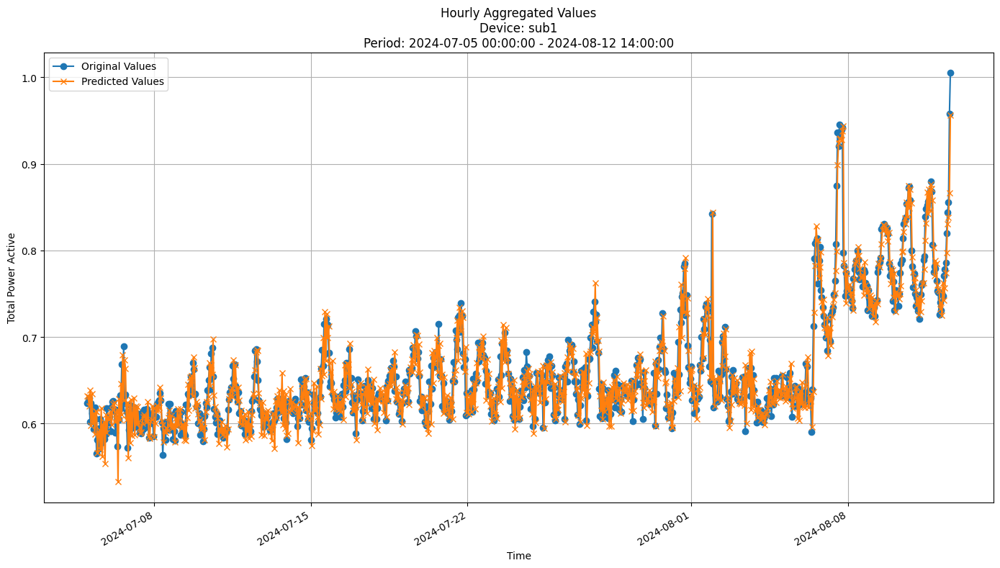


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0260
MAE: 0.0190
MAPE: 2.8926%

Directional Metrics:
Directional Accuracy: 39.3089%
First-Diff Correlation: -0.2948

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


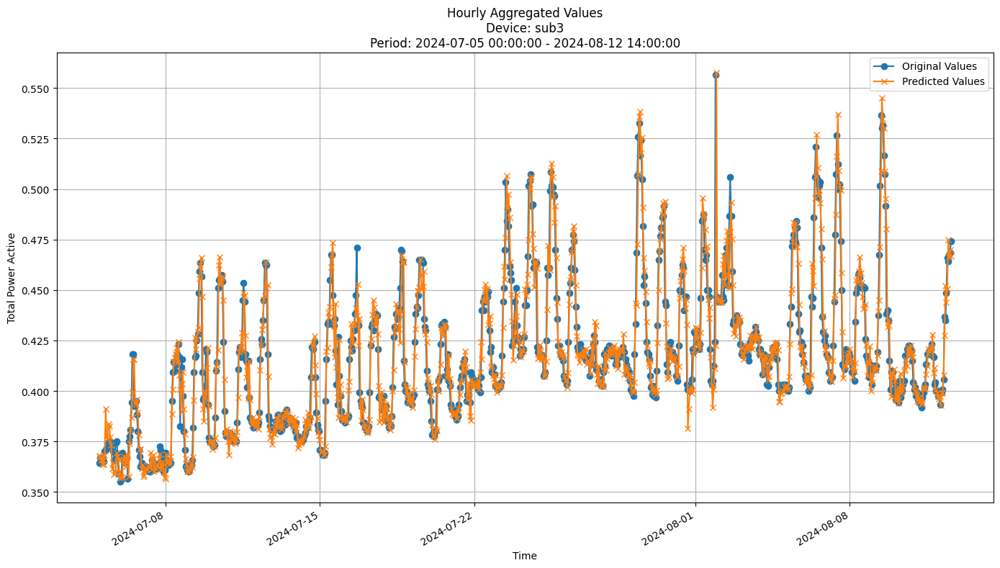


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0114
MAE: 0.0067
MAPE: 1.5656%

Directional Metrics:
Directional Accuracy: 52.5918%
First-Diff Correlation: 0.2170

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [12]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [ ]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': USE_RESIDUAL}

In [ ]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_3h', 'consumption_lag_24h']
Excluded features: []
Using features: [2, 3, 4, 5, 6, 7, 8]
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000511 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0131
	MAE: 0.0073
	MAPE: 1.7045%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.1186

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-d

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Valid features: ['hour', 'weekday', 'month', 'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_3h', 'consumption_lag_24h']
Excluded features: []
Using features: [2, 3, 4, 5, 6, 7, 8]
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000488 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0118
	MAE: 0.0071
	MAPE: 1.5945%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.3810

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-d

#### Results

In [10]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0125 ± 0.0006
	MAE: 0.0072 ± 0.0001
	MAPE: 1.6495% ± 0.0550%

	Directional Metrics:
		Directional Accuracy: 50.9526% ± 0.1652%
		First-Diff Correlation: 0.2498 ± 0.1312

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9792 ± 0.0208
		Spike F1: 0.9894 ± 0.0106
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 1.0000 ± 0.0000
		Drop F1: 1.0000 ± 0.0000
Daily Metrics:
	RMSE: 0.0167 ± 0.0076
	MAE: 0.0106 ± 0.0034
	MAPE: 0.1238% ± 0.0515%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9996 ± 0.0003

	Immediate Detection (delta=0):
		Spike

#### Validation plots

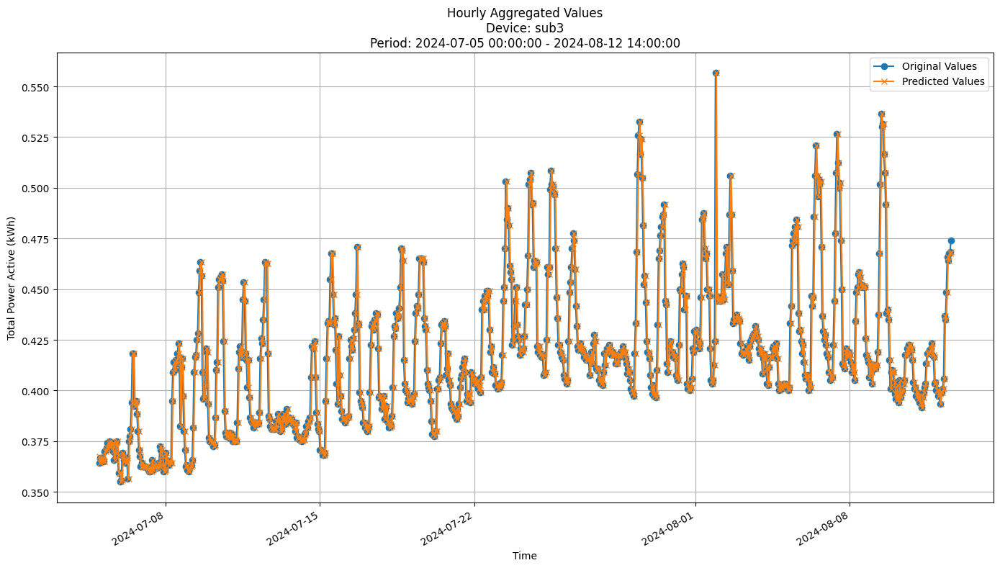


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0128
MAE: 0.0072
MAPE: 1.6742%

Directional Metrics:
Directional Accuracy: 51.0799%
First-Diff Correlation: 0.1775

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


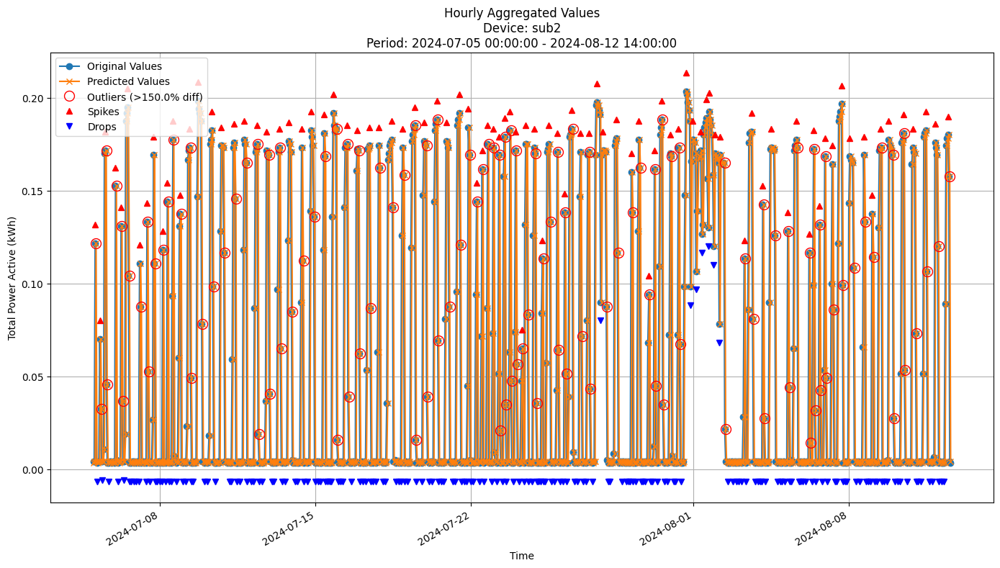


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0589
MAE: 0.0323
MAPE: 250.5989%

Directional Metrics:
Directional Accuracy: 41.5767%
First-Diff Correlation: 0.1032

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


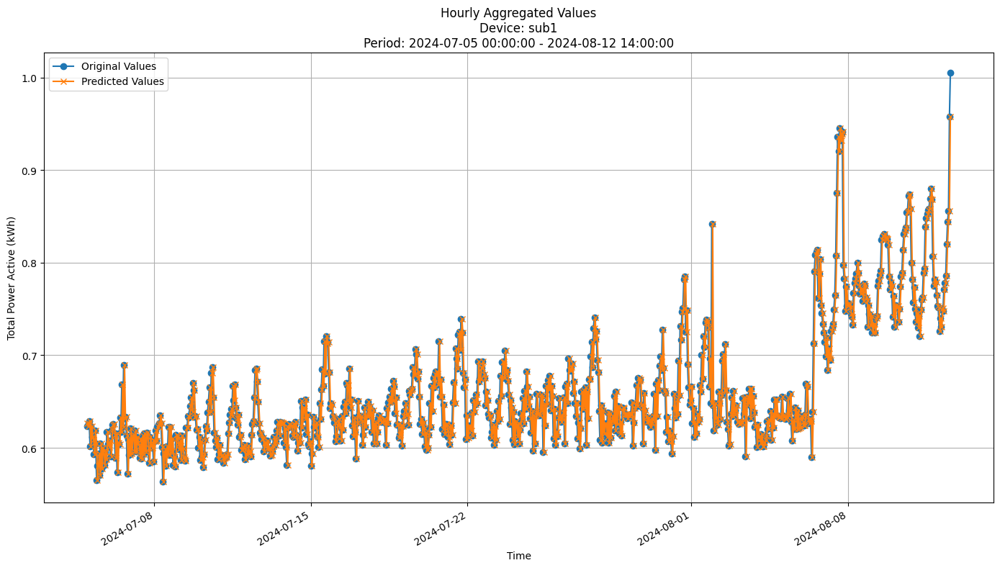


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0250
MAE: 0.0181
MAPE: 2.7465%

Directional Metrics:
Directional Accuracy: 37.0410%
First-Diff Correlation: -0.3698

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [11]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [17]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
# gbdt_params = {
#     'n_estimators': 100,
#     'learning_rate': 0.03,
#     'subsample': 0.8,
#     'max_depth': 10,
#     'random_state': 42
# }
gbdt_params = {'n_estimators': 100, 
 'learning_rate': 0.05, 
 'max_depth': 3, 
 'subsample': 0.6, 
 'random_state': 42}

In [ ]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.11 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.08 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.010811 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0492
	MAE: 0.0351
	MAPE: 353.0564%

Directional Metrics:
	Directional Accuracy: 57.6751%
	First-Diff Correlation: 0.2824

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3467
		Recall: 0.3611
		F1: 0.3537
	Drops:
		Precision: 0.3378
		Recall: 0.1880
		F1: 0.2415

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.10 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.010620 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0466
	MAE: 0.0339
	MAPE: 415.2691%

Directional Metrics:
	Directional Accuracy: 58.2677%
	First-Diff Correlation: 0.2331

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3043
		Recall: 0.2917
		F1: 0.2979
	Drops:
		Precision: 0.4783
		Recall: 0.2075
		F1: 0.2895

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9130
		Recall: 0.8750
		F1: 0.8936
	Drops:
		Precision: 1.0000
		Recall: 0.4340
		F1: 0.6053
------------------------------------------------

#### Results

In [19]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0409 ± 0.0017
	MAE: 0.0286 ± 0.0011
	MAPE: 345.3713% ± 0.5003%

	Directional Metrics:
		Directional Accuracy: 59.1723% ± 0.0814%
		First-Diff Correlation: 0.3526 ± 0.0192

	Immediate Detection (delta=0):
		Spike Precision: 0.4295 ± 0.0116
		Spike Recall: 0.4328 ± 0.0020
		Spike F1: 0.4311 ± 0.0069
		Drop Precision: 0.3011 ± 0.0175
		Drop Recall: 0.1486 ± 0.0089
		Drop F1: 0.1990 ± 0.0118

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8999 ± 0.0193
		Spike Recall: 0.9067 ± 0.0009
		Spike F1: 0.9032 ± 0.0092
		Drop Precision: 0.7359 ± 0.0344
		Drop Recall: 0.3633 ± 0.0177
		Drop F1: 0.4864 ± 0.0234
Daily Metrics:
	RMSE: 0.1340 ± 0.0111
	MAE: 0.1041 ± 0.0094
	MAPE: 12.0061% ± 0.0399%

	Directional Metrics:
		Directional Accuracy: 92.6936% ± 3.6027%
		First-Diff Correlation: 0.9279 ± 0.0064

	Immediate Detection (delta=0):
		Spi

#### Training plots

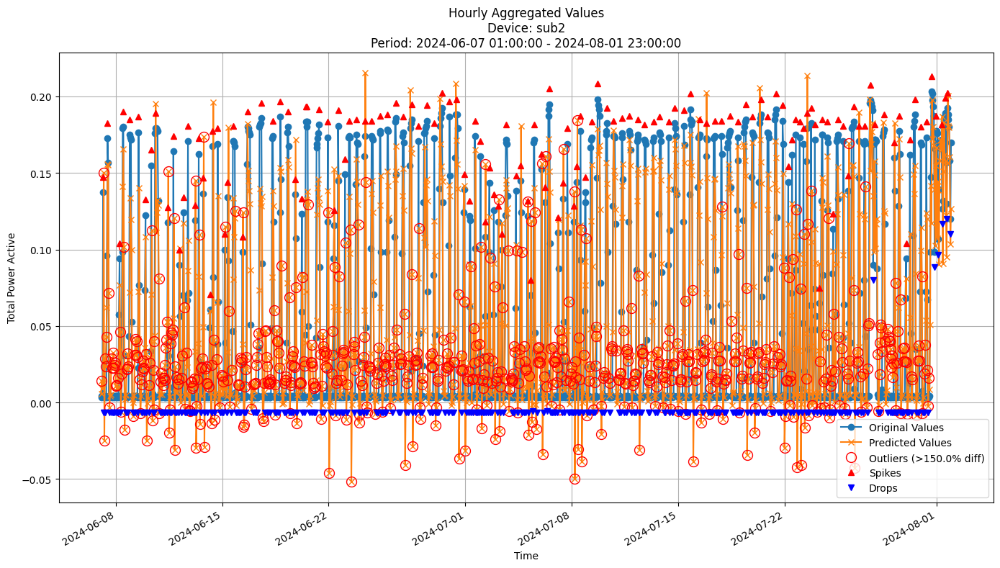


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0426
MAE: 0.0298
MAPE: 345.8716%

Directional Metrics:
Directional Accuracy: 59.0909%
First-Diff Correlation: 0.3334

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3750
  Recall: 0.0219
  F1 Score: 0.0414
Drops:
  Precision: 0.3333
  Recall: 0.0111
  F1 Score: 0.0214

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7500
  Recall: 0.0438
  F1 Score: 0.0828
Drops:
  Precision: 0.6667
  Recall: 0.0221
  F1 Score: 0.0429


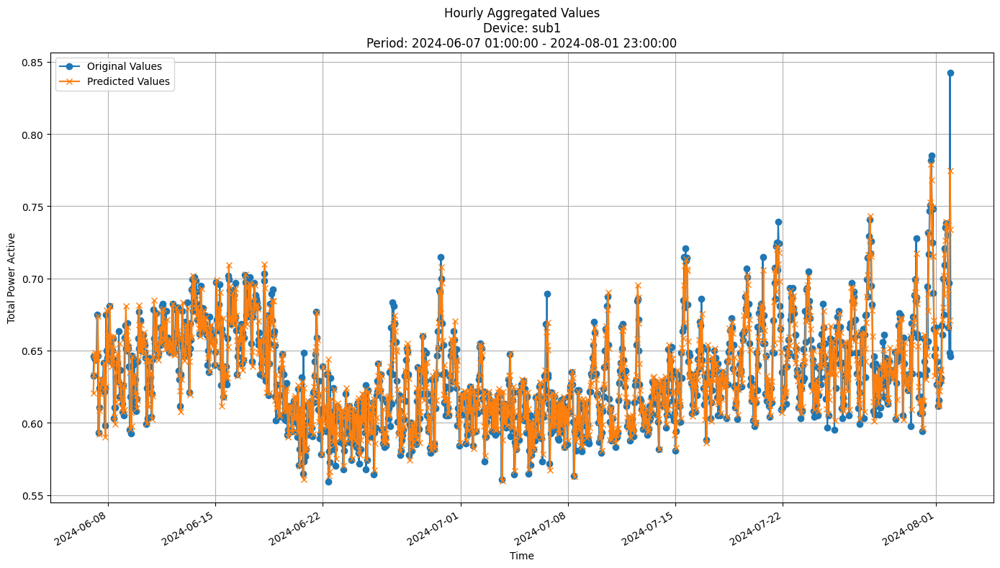


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0203
MAE: 0.0158
MAPE: 2.5010%

Directional Metrics:
Directional Accuracy: 36.5127%
First-Diff Correlation: -0.2886

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


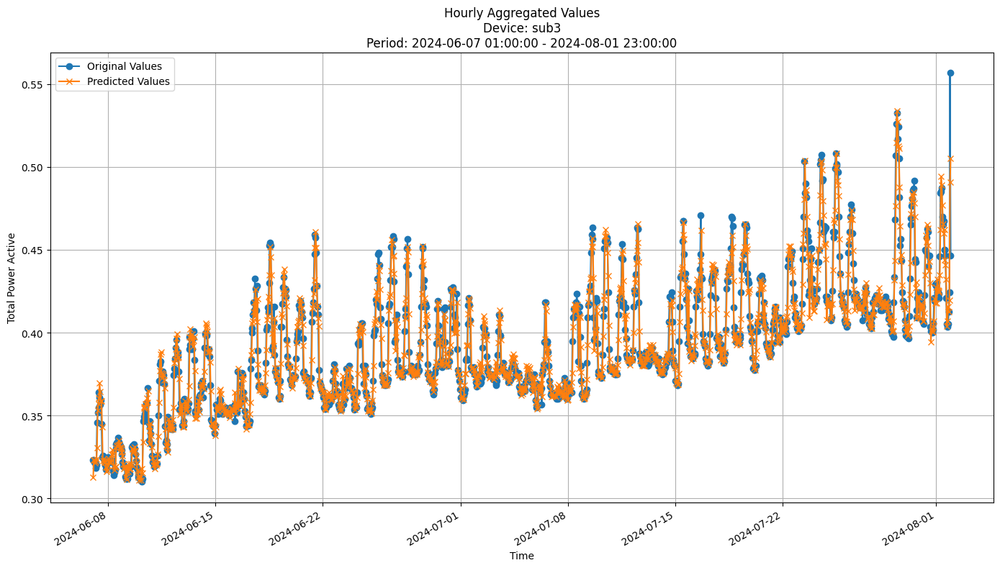


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0082
MAE: 0.0054
MAPE: 1.3510%

Directional Metrics:
Directional Accuracy: 53.5768%
First-Diff Correlation: 0.4236

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [20]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

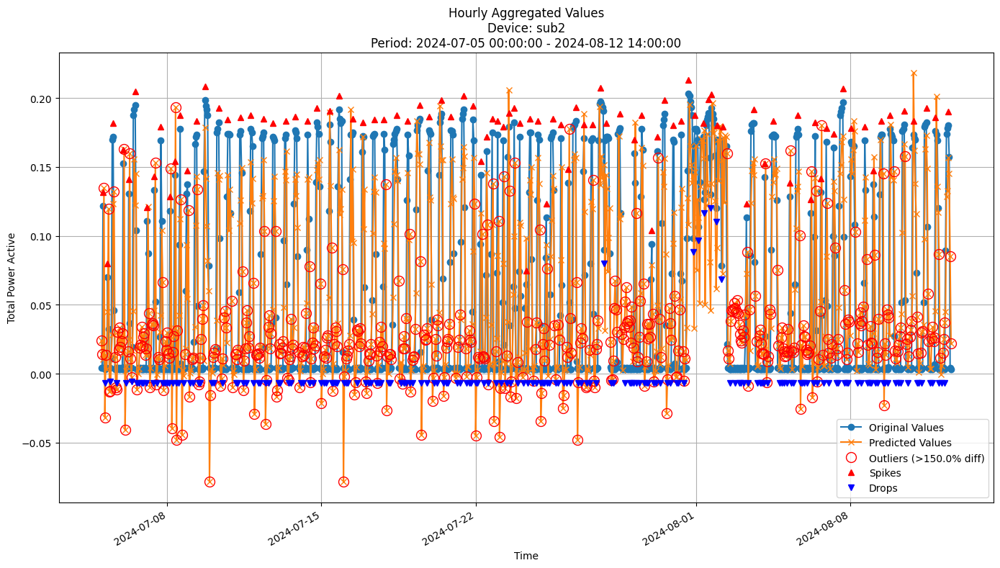


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0485
MAE: 0.0348
MAPE: 370.1699%

Directional Metrics:
Directional Accuracy: 57.7754%
First-Diff Correlation: 0.2705

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 0.0104
  F1 Score: 0.0206
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.0104
  F1 Score: 0.0206
Drops:
  Precision: 0.5000
  Recall: 0.0054
  F1 Score: 0.0106


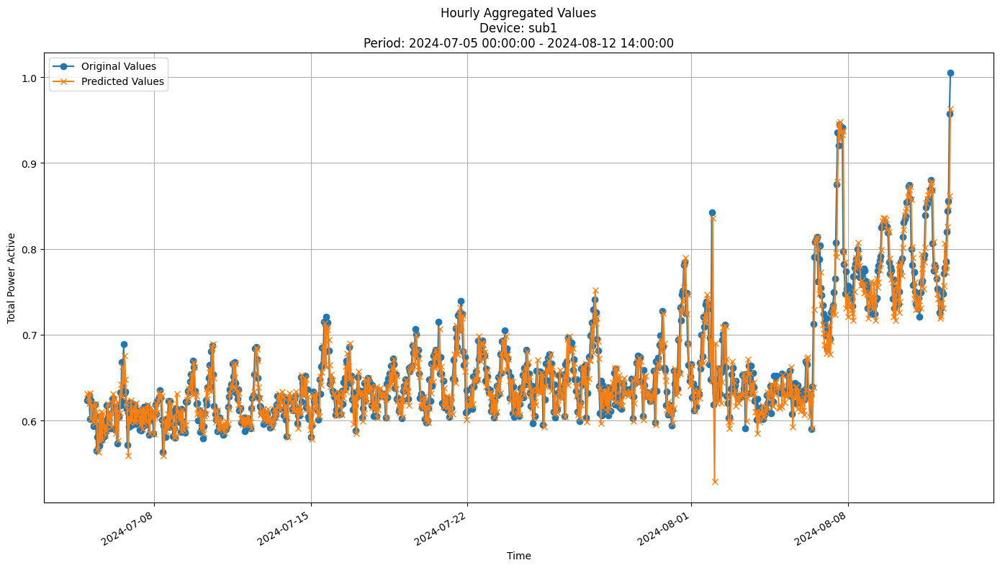


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0255
MAE: 0.0187
MAPE: 2.8214%

Directional Metrics:
Directional Accuracy: 37.6890%
First-Diff Correlation: -0.3266

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


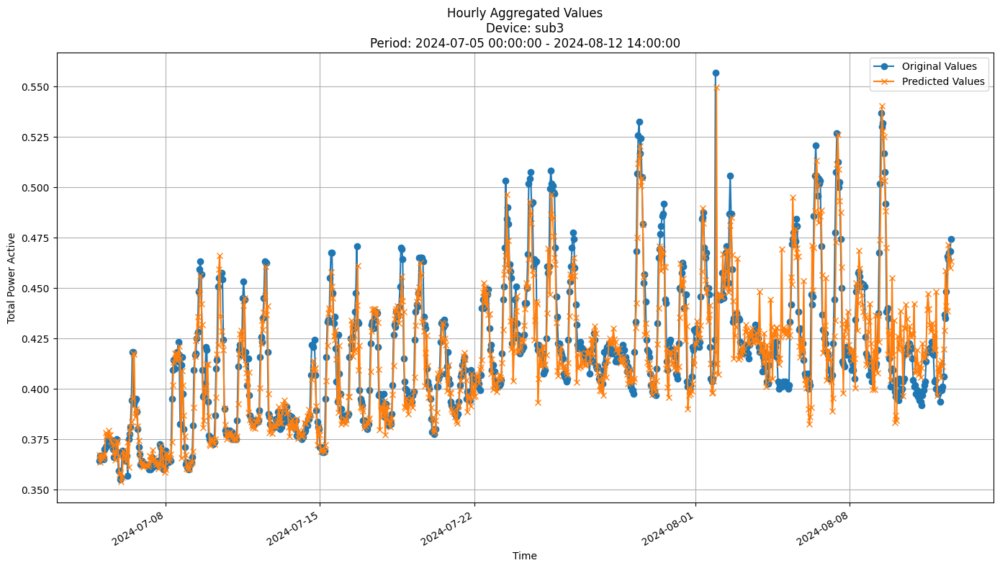


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0144
MAE: 0.0096
MAPE: 2.2331%

Directional Metrics:
Directional Accuracy: 50.1080%
First-Diff Correlation: 0.1457

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [21]:
join_periods = [-2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [22]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {'n_estimators': 300, 
 'max_depth': 7, 
 'max_features': 1.0, 
 'random_state': 42, 
 'n_jobs': -1}

In [ ]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.37 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.31 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.119888 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0489
	MAE: 0.0338
	MAPE: 327.6205%

Directional Metrics:
	Directional Accuracy: 54.9925%
	First-Diff Correlation: 0.3091

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3636
		Recall: 0.3889
		F1: 0.3758
	Drops:
		Precision: 0.2727
		Recall: 0.1579
		F1: 0.2000

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.34 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.119881 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0488
	MAE: 0.0359
	MAPE: 444.9217%

Directional Metrics:
	Directional Accuracy: 53.5433%
	First-Diff Correlation: 0.2094

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3478
		Recall: 0.3333
		F1: 0.3404
	Drops:
		Precision: 0.3913
		Recall: 0.1698
		F1: 0.2368

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9565
		Recall: 0.9167
		F1: 0.9362
	Drops:
		Precision: 1.0000
		Recall: 0.4340
		F1: 0.6053
------------------------------------------------

#### Results

In [24]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0346 ± 0.0019
	MAE: 0.0235 ± 0.0011
	MAPE: 273.9004% ± 4.0908%

	Directional Metrics:
		Directional Accuracy: 59.2469% ± 0.1560%
		First-Diff Correlation: 0.5374 ± 0.0305

	Immediate Detection (delta=0):
		Spike Precision: 0.5039 ± 0.0184
		Spike Recall: 0.5120 ± 0.0265
		Spike F1: 0.5079 ± 0.0224
		Drop Precision: 0.2611 ± 0.0075
		Drop Recall: 0.1303 ± 0.0021
		Drop F1: 0.1738 ± 0.0035

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8857 ± 0.0201
		Spike Recall: 0.8991 ± 0.0067
		Spike F1: 0.8923 ± 0.0135
		Drop Precision: 0.7425 ± 0.0111
		Drop Recall: 0.3706 ± 0.0103
		Drop F1: 0.4944 ± 0.0117
Daily Metrics:
	RMSE: 0.1226 ± 0.0077
	MAE: 0.0981 ± 0.0022
	MAPE: 11.5412% ± 0.5376%

	Directional Metrics:
		Directional Accuracy: 90.8418% ± 1.7508%
		First-Diff Correlation: 0.9397 ± 0.0035

	Immediate Detection (delta=0):
		Spi

#### Training plots
Plot only the last period of predictions

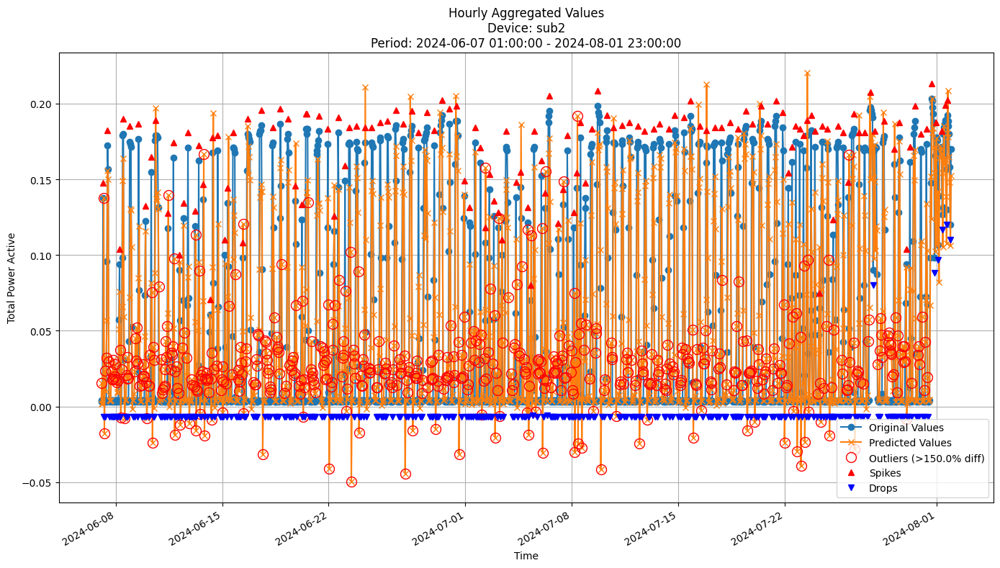


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0365
MAE: 0.0246
MAPE: 277.9912%

Directional Metrics:
Directional Accuracy: 59.0909%
First-Diff Correlation: 0.5069

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4167
  Recall: 0.0365
  F1 Score: 0.0671
Drops:
  Precision: 0.3333
  Recall: 0.0148
  F1 Score: 0.0283

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.0730
  F1 Score: 0.1342
Drops:
  Precision: 0.6667
  Recall: 0.0295
  F1 Score: 0.0565


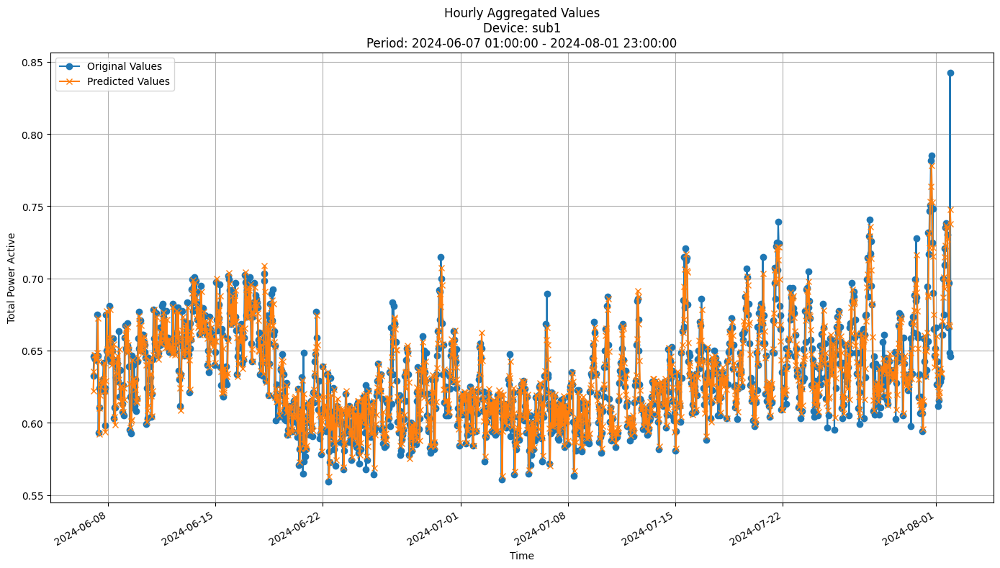


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0187
MAE: 0.0146
MAPE: 2.3068%

Directional Metrics:
Directional Accuracy: 40.3875%
First-Diff Correlation: -0.1899

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


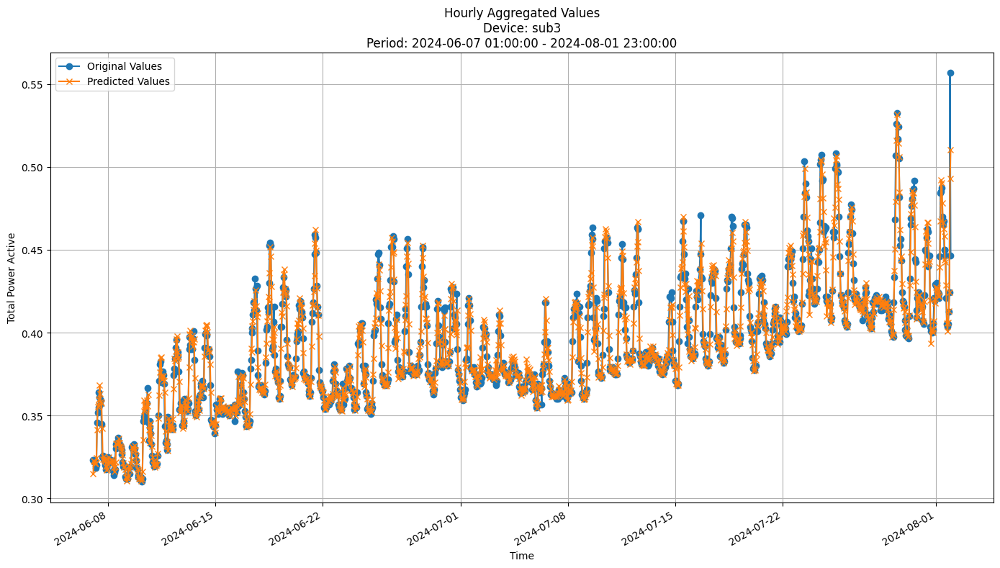


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0070
MAE: 0.0046
MAPE: 1.1468%

Directional Metrics:
Directional Accuracy: 54.2474%
First-Diff Correlation: 0.5505

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [25]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

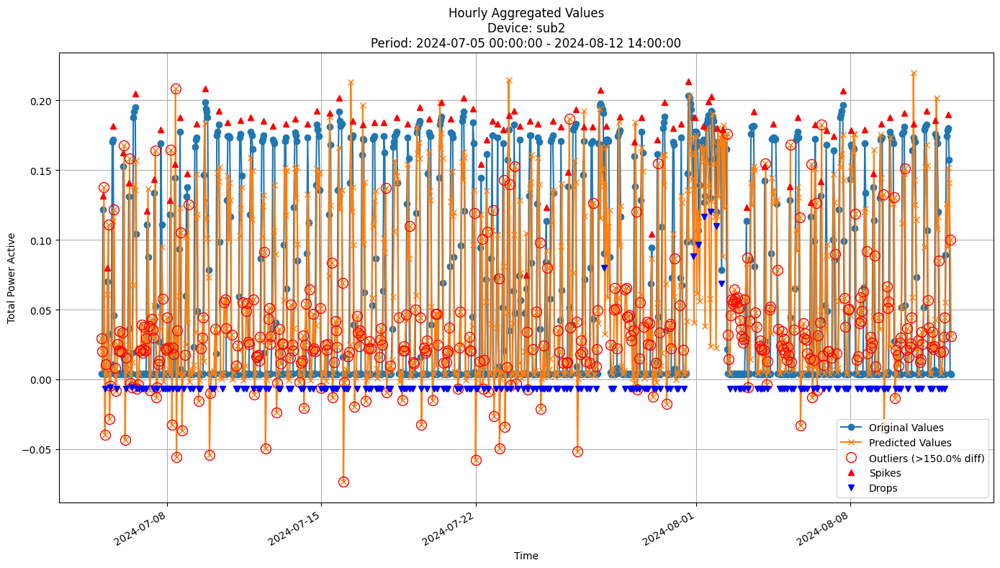


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0488
MAE: 0.0344
MAPE: 359.8878%

Directional Metrics:
Directional Accuracy: 54.5356%
First-Diff Correlation: 0.2853

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 1.0000
  Recall: 0.0054
  F1 Score: 0.0107


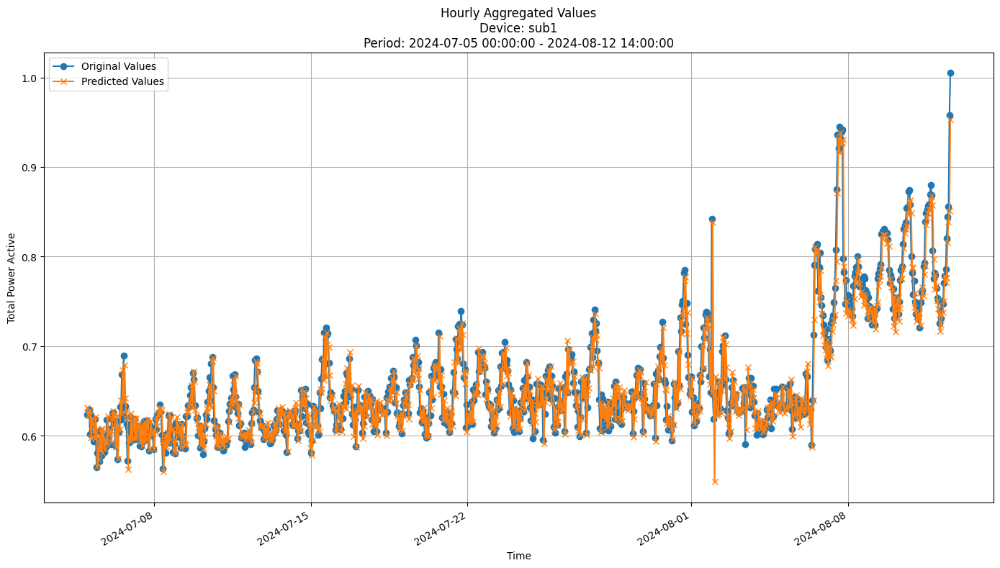


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0251
MAE: 0.0183
MAPE: 2.7670%

Directional Metrics:
Directional Accuracy: 38.1210%
First-Diff Correlation: -0.3474

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


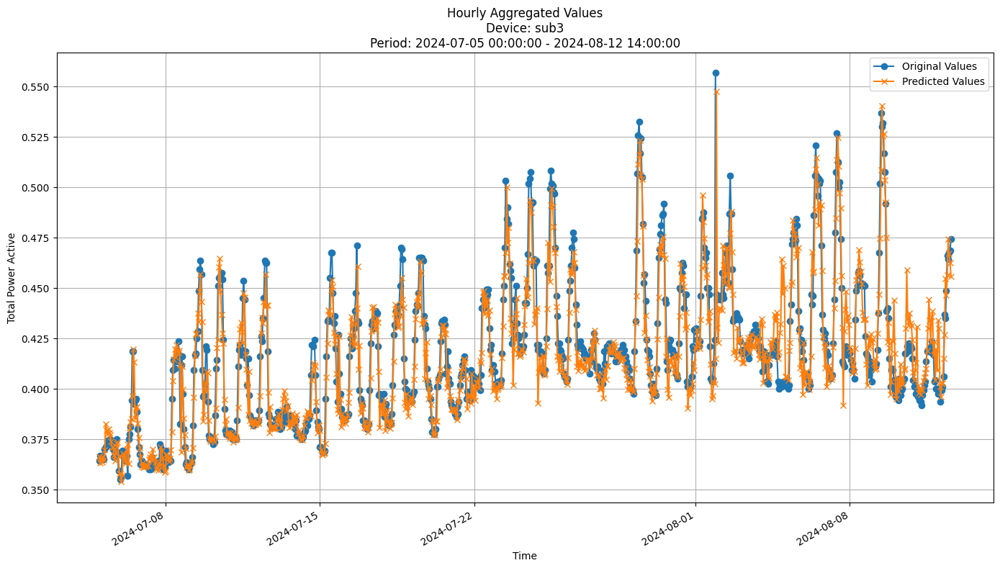


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0132
MAE: 0.0086
MAPE: 1.9974%

Directional Metrics:
Directional Accuracy: 51.2959%
First-Diff Correlation: 0.1815

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [26]:
join_periods = [-2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [27]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
# hoef_params = {
#     'grace_period': 10,
#     'delta': 0.5,
#     'max_depth': 10,
#     'tau': 0.05,
#     'leaf_prediction': 'mean'
# }
hoef_params = {'max_depth': 10,
'grace_period': 96,
'tau': 0.001,
'delta': 0.005}

In [ ]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.076187 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0553
	MAE: 0.0376
	MAPE: 328.9815%

Directional Metrics:
	Directional Accuracy: 48.1371%
	First-Diff Correlation: 0.1390

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2639
		Recall: 0.2639
		F1: 0.2639
	Drops:
		Precision: 0.2113
		Recall: 0.1128
		F1: 0.1471

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9444
		Recall: 0.9444
		F1: 0.9444
	Drops:
		Precision: 0.7324
		Recall: 0.3910
		F1: 0.5098
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.070961 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0513
	MAE: 0.0330
	MAPE: 257.7554%

Directional Metrics:
	Directional Accuracy: 43.3071%
	First-Diff Correlation: 0.1260

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1304
		Recall: 0.1250
		F1: 0.1277
	Drops:
		Precision: 0.2609
		Recall: 0.1132
		F1: 0.1579

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9565
		Recall: 0.9167
		F1: 0.9362
	Drops:
		Precision: 0.9130
		Recall: 0.3962
		F1: 0.5526
--------------------------------------------------
Dai

#### Results

In [29]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0530 ± 0.0010
	MAE: 0.0347 ± 0.0012
	MAPE: 379.8070% ± 87.4924%

	Directional Metrics:
		Directional Accuracy: 41.3117% ± 1.0132%
		First-Diff Correlation: 0.0870 ± 0.0159

	Immediate Detection (delta=0):
		Spike Precision: 0.1786 ± 0.0045
		Spike Recall: 0.1978 ± 0.0022
		Spike F1: 0.1877 ± 0.0034
		Drop Precision: 0.1472 ± 0.0006
		Drop Recall: 0.0991 ± 0.0035
		Drop F1: 0.1184 ± 0.0023

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9029 ± 0.0126
		Spike Recall: 1.0000 ± 0.0000
		Spike F1: 0.9489 ± 0.0070
		Drop Precision: 0.7738 ± 0.0011
		Drop Recall: 0.5211 ± 0.0211
		Drop F1: 0.6225 ± 0.0154
Daily Metrics:
	RMSE: 0.1929 ± 0.0698
	MAE: 0.1547 ± 0.0545
	MAPE: 14.5502% ± 1.3888%

	Directional Metrics:
		Directional Accuracy: 88.9562% ± 3.7710%
		First-Diff Correlation: 0.9547 ± 0.0066

	Immediate Detection (delta=0):
		Sp

#### Training plots
Plot only the last period of predictions

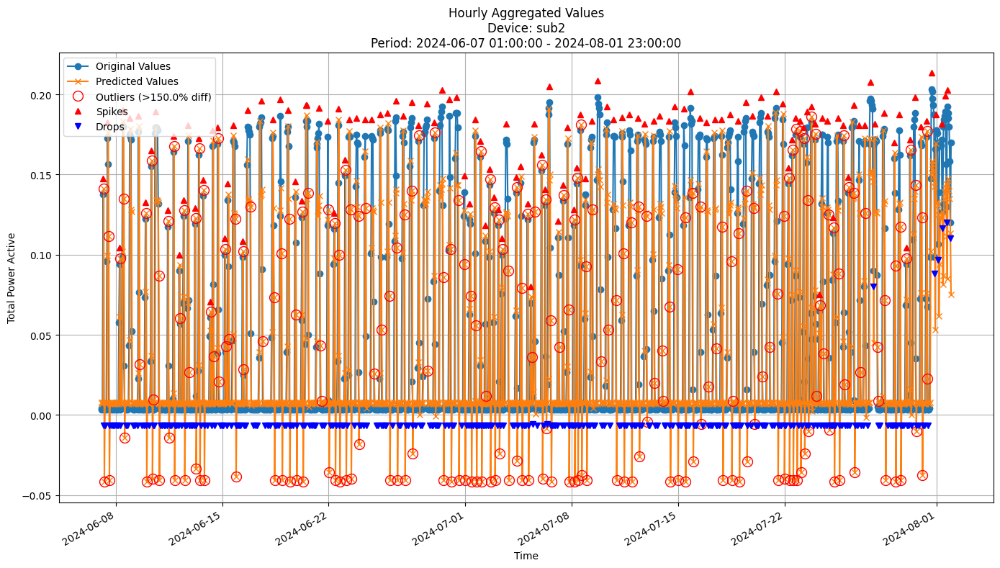


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0540
MAE: 0.0335
MAPE: 292.3146%

Directional Metrics:
Directional Accuracy: 42.3249%
First-Diff Correlation: 0.1028

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1971
  Recall: 0.1971
  F1 Score: 0.1971
Drops:
  Precision: 0.1647
  Recall: 0.1033
  F1 Score: 0.1270

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9489
  Recall: 0.9489
  F1 Score: 0.9489
Drops:
  Precision: 0.8353
  Recall: 0.5240
  F1 Score: 0.6440


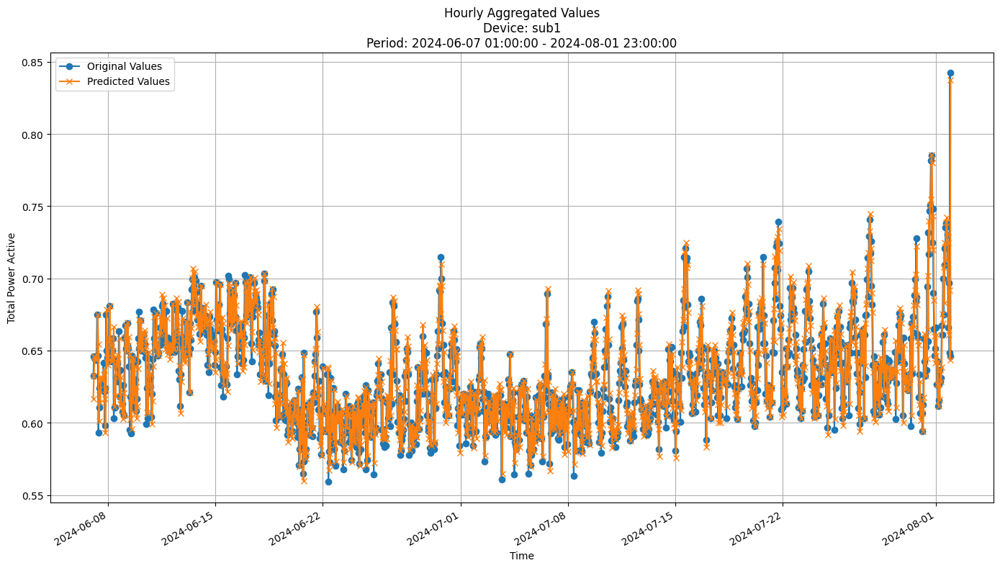


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0234
MAE: 0.0176
MAPE: 2.7799%

Directional Metrics:
Directional Accuracy: 34.1282%
First-Diff Correlation: -0.4972

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


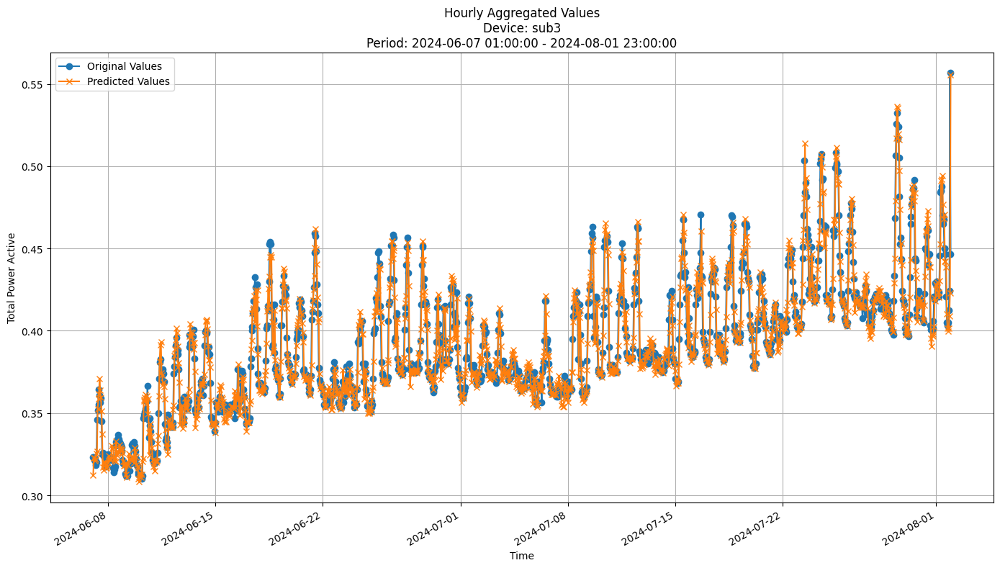


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0104
MAE: 0.0066
MAPE: 1.6364%

Directional Metrics:
Directional Accuracy: 52.0119%
First-Diff Correlation: 0.1999

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [30]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

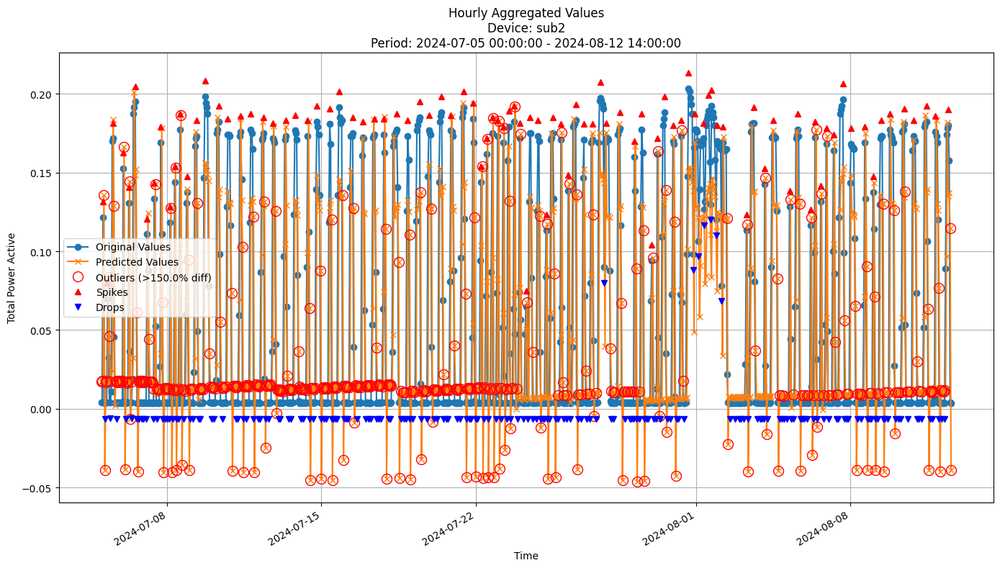


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0542
MAE: 0.0364
MAPE: 309.3886%

Directional Metrics:
Directional Accuracy: 46.7603%
First-Diff Correlation: 0.1357

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2391
  Recall: 0.2292
  F1 Score: 0.2340
Drops:
  Precision: 0.2308
  Recall: 0.1129
  F1 Score: 0.1516

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9457
  Recall: 0.9062
  F1 Score: 0.9255
Drops:
  Precision: 0.7802
  Recall: 0.3817
  F1 Score: 0.5126


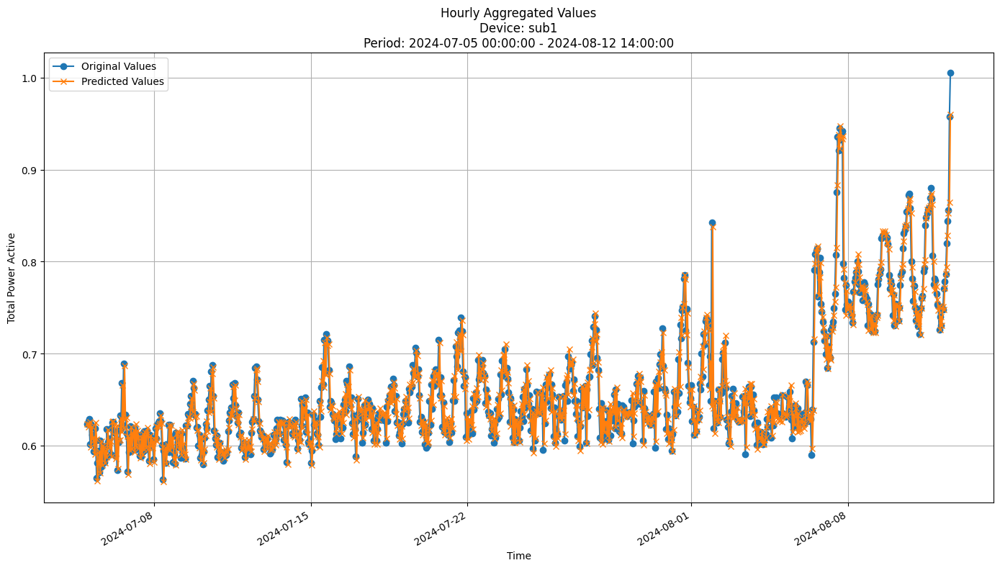


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0246
MAE: 0.0179
MAPE: 2.7182%

Directional Metrics:
Directional Accuracy: 36.0691%
First-Diff Correlation: -0.3705

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


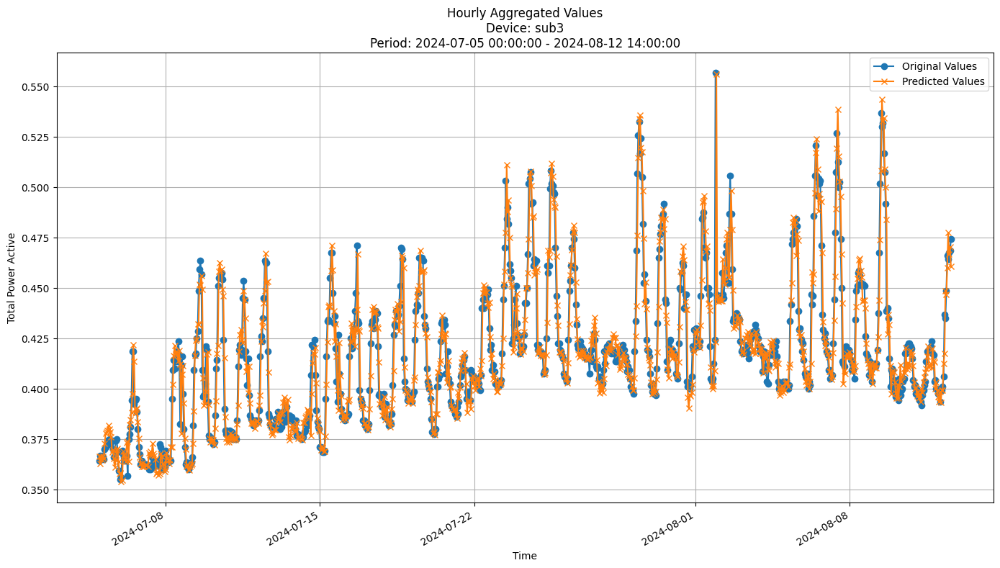


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0116
MAE: 0.0071
MAPE: 1.6457%

Directional Metrics:
Directional Accuracy: 51.1879%
First-Diff Correlation: 0.1896

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [31]:
join_periods = [-2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [32]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 10,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}

In [ ]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 3.624046 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0562
	MAE: 0.0361
	MAPE: 340.9328%

Directional Metrics:
	Directional Accuracy: 55.4396%
	First-Diff Correlation: 0.1181

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1216
		Recall: 0.1250
		F1: 0.1233
	Drops:
		Precision: 0.3288
		Recall: 0.1805
		F1: 0.2330

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8649
		Recall: 0.8889
		F1: 0.8767
	Drops:
		Precision: 0.7945
		Recall: 0.4361
		F1: 0.5631
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 3.916084 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0521
	MAE: 0.0330
	MAPE: 316.8548%

Directional Metrics:
	Directional Accuracy: 52.7559%
	First-Diff Correlation: 0.1052

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0769
		Recall: 0.0833
		F1: 0.0800
	Drops:
		Precision: 0.3600
		Recall: 0.1698
		F1: 0.2308

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8077
		Recall: 0.8750
		F1: 0.8400
	Drops:
		Precision: 1.0000
		Recall: 0.4717
		F1: 0.6410
--------------------------------------------------
Dai

#### Results

In [34]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0520 ± 0.0006
	MAE: 0.0320 ± 0.0013
	MAPE: 356.0284% ± 4.6179%

	Directional Metrics:
		Directional Accuracy: 54.9580% ± 1.3759%
		First-Diff Correlation: 0.1017 ± 0.0194

	Immediate Detection (delta=0):
		Spike Precision: 0.1597 ± 0.0082
		Spike Recall: 0.1639 ± 0.0100
		Spike F1: 0.1617 ± 0.0091
		Drop Precision: 0.2751 ± 0.0630
		Drop Recall: 0.1394 ± 0.0364
		Drop F1: 0.1850 ± 0.0464

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8805 ± 0.0134
		Spike Recall: 0.9031 ± 0.0046
		Spike F1: 0.8917 ± 0.0091
		Drop Precision: 0.7025 ± 0.0510
		Drop Recall: 0.3541 ± 0.0379
		Drop F1: 0.4707 ± 0.0450
Daily Metrics:
	RMSE: 0.1046 ± 0.0084
	MAE: 0.0804 ± 0.0089
	MAPE: 8.3789% ± 0.3412%

	Directional Metrics:
		Directional Accuracy: 92.6599% ± 0.0673%
		First-Diff Correlation: 0.9437 ± 0.0170

	Immediate Detection (delta=0):
		Spik

#### Training plots

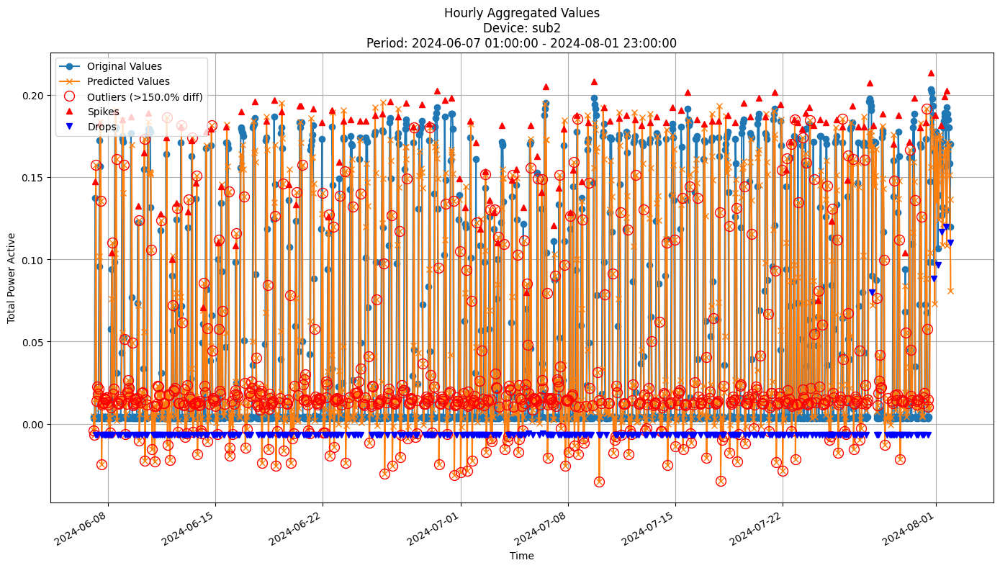


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0526
MAE: 0.0333
MAPE: 360.6463%

Directional Metrics:
Directional Accuracy: 56.3338%
First-Diff Correlation: 0.1211

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1780
  Recall: 0.1533
  F1 Score: 0.1647
Drops:
  Precision: 0.3729
  Recall: 0.1624
  F1 Score: 0.2262

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9153
  Recall: 0.7883
  F1 Score: 0.8471
Drops:
  Precision: 0.7797
  Recall: 0.3395
  F1 Score: 0.4730


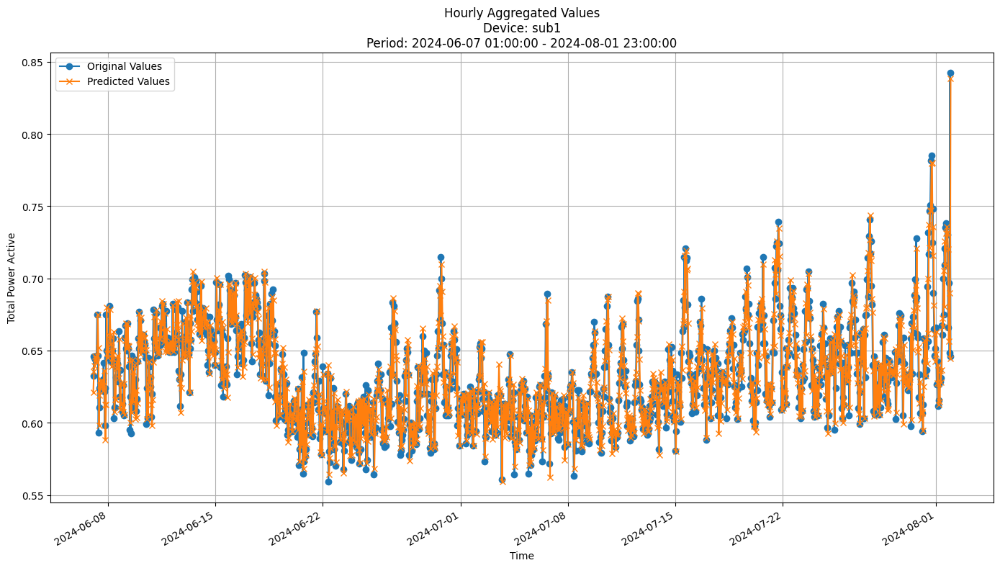


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0228
MAE: 0.0170
MAPE: 2.6843%

Directional Metrics:
Directional Accuracy: 34.2027%
First-Diff Correlation: -0.4797

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


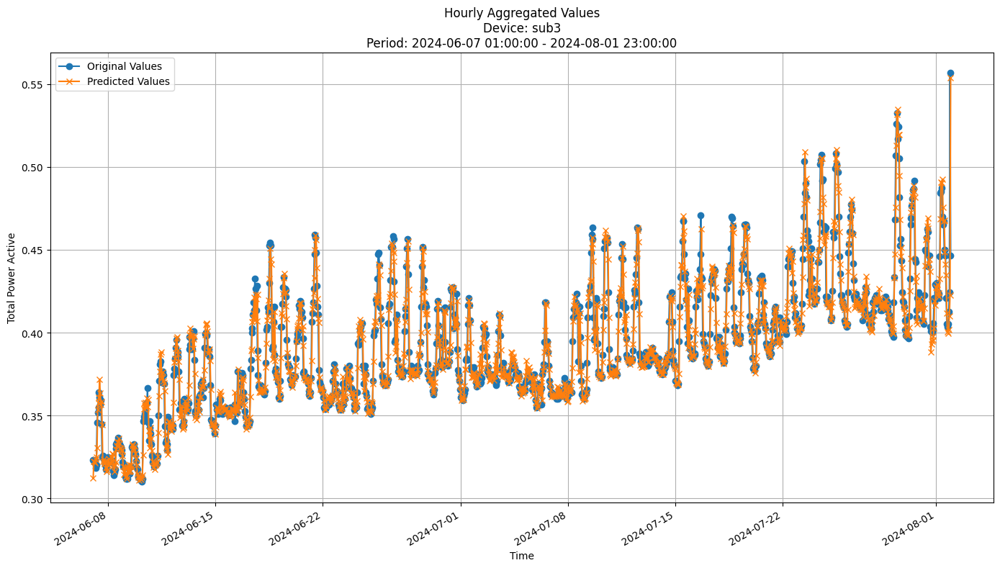


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0097
MAE: 0.0057
MAPE: 1.4158%

Directional Metrics:
Directional Accuracy: 52.6826%
First-Diff Correlation: 0.2391

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [35]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

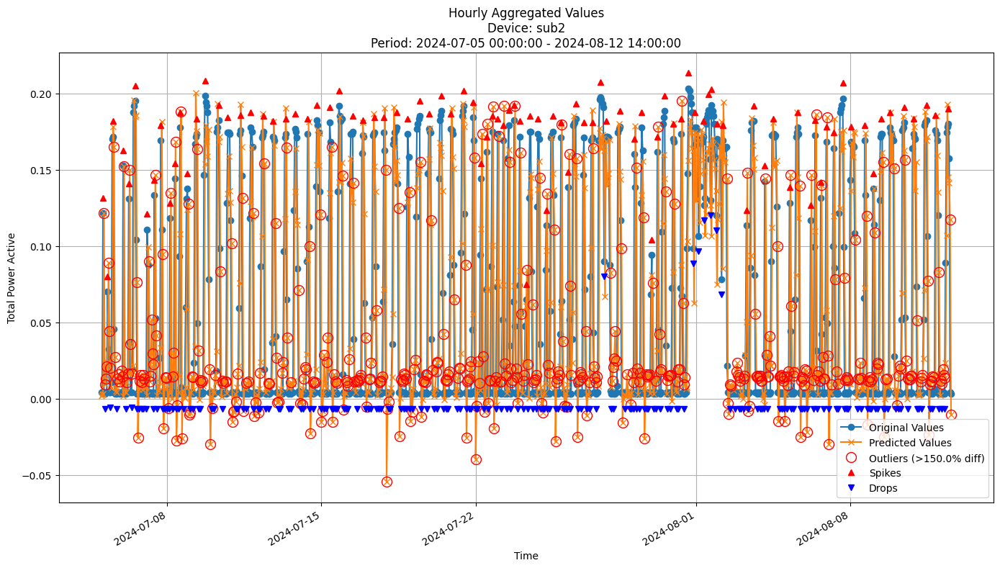


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0551
MAE: 0.0352
MAPE: 334.3094%

Directional Metrics:
Directional Accuracy: 54.6436%
First-Diff Correlation: 0.1149

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1200
  Recall: 0.0938
  F1 Score: 0.1053
Drops:
  Precision: 0.3514
  Recall: 0.1398
  F1 Score: 0.2000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9067
  Recall: 0.7083
  F1 Score: 0.7953
Drops:
  Precision: 0.8243
  Recall: 0.3280
  F1 Score: 0.4692


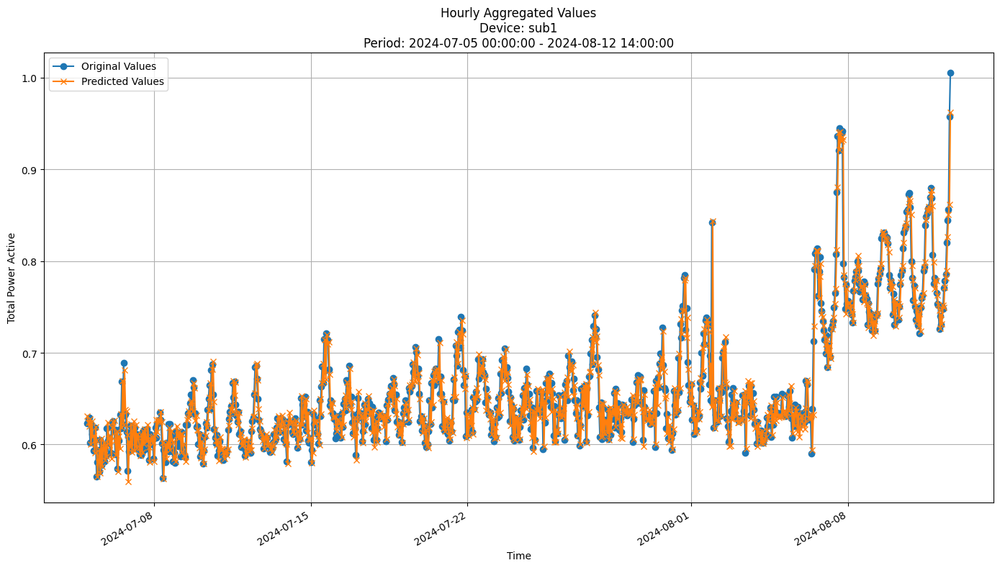


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0246
MAE: 0.0178
MAPE: 2.7124%

Directional Metrics:
Directional Accuracy: 36.7171%
First-Diff Correlation: -0.3610

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


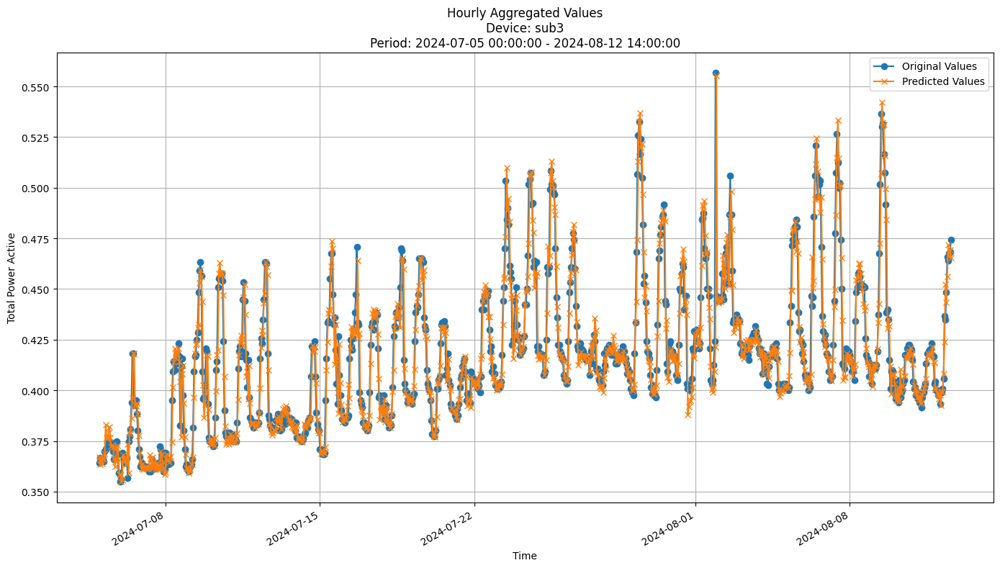


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0113
MAE: 0.0065
MAPE: 1.5106%

Directional Metrics:
Directional Accuracy: 51.8359%
First-Diff Correlation: 0.2054

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [36]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [37]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {'depth': 30, 
               'grace_period': 96, 
               'grace_period_depth': 0, 
               'split_confidence': 0.1, 
               'max_feature': 0.7, 
               'tie_threshold': 0.05, 
               'bin_type': 'adaptive', 
               'max_bins': 16, 
               'split_criterion': 'vr_rel'}

In [ ]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 2.882568 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0662
	MAE: 0.0425
	MAPE: 480.5474%

Directional Metrics:
	Directional Accuracy: 54.6945%
	First-Diff Correlation: 0.1998

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1842
		Recall: 0.2917
		F1: 0.2258
	Drops:
		Precision: 0.2087
		Recall: 0.1805
		F1: 0.1935

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5614
		Recall: 0.8889
		F1: 0.6882
	Drops:
		Precision: 0.6609
		Recall: 0.5714
		F1: 0.6129
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 3.761993 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0693
	MAE: 0.0450
	MAPE: 541.0956%

Directional Metrics:
	Directional Accuracy: 49.2126%
	First-Diff Correlation: 0.0682

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1220
		Recall: 0.2083
		F1: 0.1538
	Drops:
		Precision: 0.1905
		Recall: 0.1509
		F1: 0.1684

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5366
		Recall: 0.9167
		F1: 0.6769
	Drops:
		Precision: 0.6667
		Recall: 0.5283
		F1: 0.5895
--------------------------------------------------
Dai

#### Results

In [39]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0695 ± 0.0005
	MAE: 0.0428 ± 0.0013
	MAPE: 565.4095% ± 25.7857%

	Directional Metrics:
		Directional Accuracy: 53.5022% ± 3.5022%
		First-Diff Correlation: 0.0941 ± 0.0294

	Immediate Detection (delta=0):
		Spike Precision: 0.1467 ± 0.0150
		Spike Recall: 0.2685 ± 0.0069
		Spike F1: 0.1895 ± 0.0142
		Drop Precision: 0.2079 ± 0.0607
		Drop Recall: 0.1889 ± 0.0492
		Drop F1: 0.1979 ± 0.0545

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4981 ± 0.0253
		Spike Recall: 0.9149 ± 0.0236
		Spike F1: 0.6442 ± 0.0153
		Drop Precision: 0.6203 ± 0.0078
		Drop Recall: 0.5688 ± 0.0121
		Drop F1: 0.5933 ± 0.0030
Daily Metrics:
	RMSE: 0.3335 ± 0.0512
	MAE: 0.2707 ± 0.0440
	MAPE: 28.3198% ± 5.4674%

	Directional Metrics:
		Directional Accuracy: 66.9360% ± 3.9731%
		First-Diff Correlation: 0.5898 ± 0.1163

	Immediate Detection (delta=0):
		Sp

#### Training plots

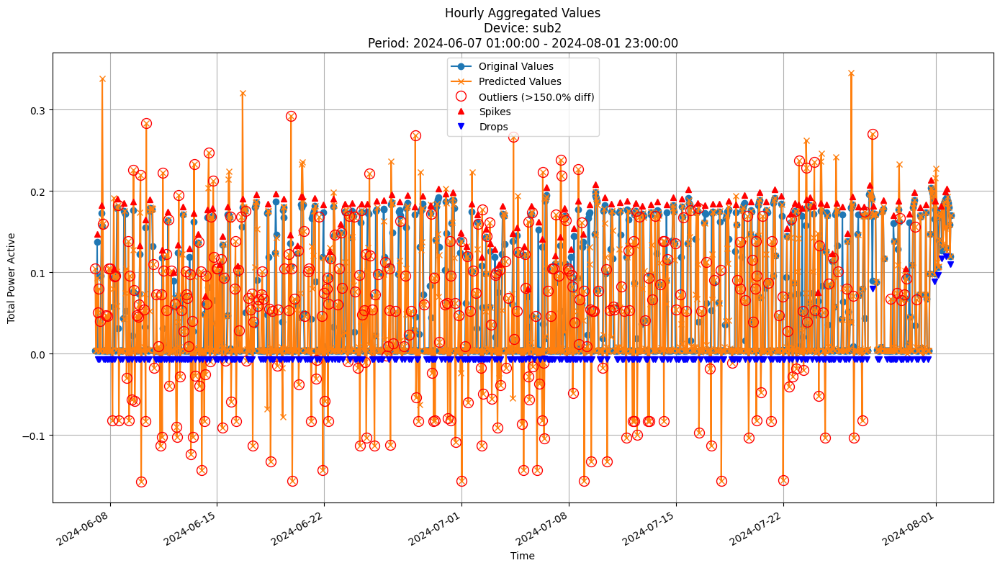


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0690
MAE: 0.0415
MAPE: 539.6238%

Directional Metrics:
Directional Accuracy: 57.0045%
First-Diff Correlation: 0.1235

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2885
  Recall: 0.1095
  F1 Score: 0.1587
Drops:
  Precision: 0.2308
  Recall: 0.0443
  F1 Score: 0.0743

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8654
  Recall: 0.3285
  F1 Score: 0.4762
Drops:
  Precision: 0.7308
  Recall: 0.1402
  F1 Score: 0.2353


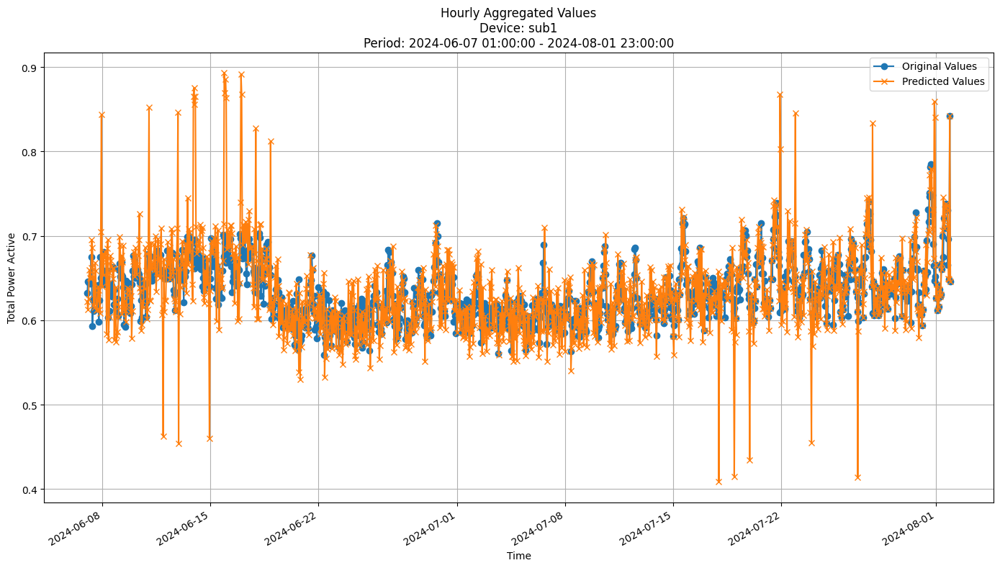


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0413
MAE: 0.0265
MAPE: 4.1716%

Directional Metrics:
Directional Accuracy: 44.7094%
First-Diff Correlation: -0.0578

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


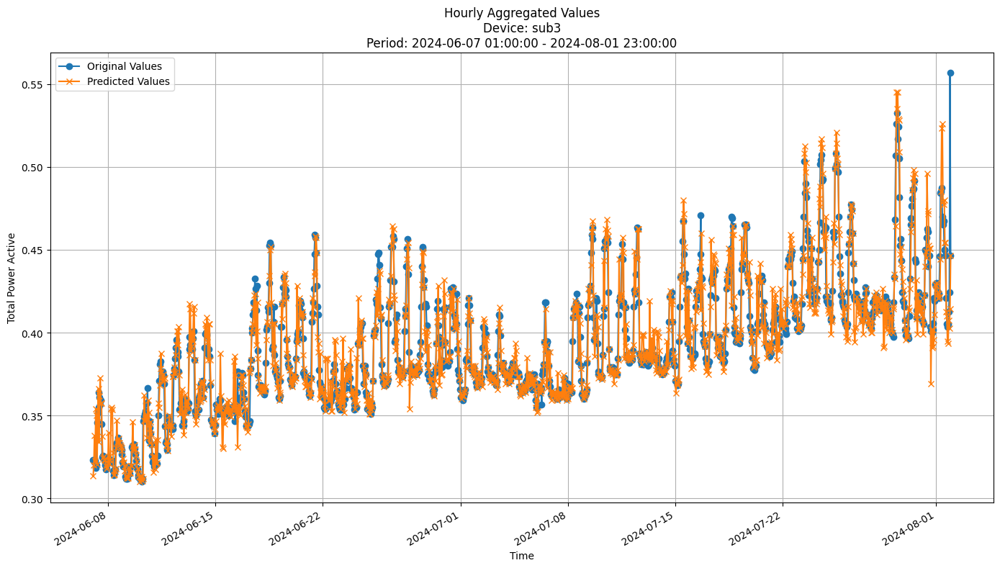


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0127
MAE: 0.0078
MAPE: 1.9532%

Directional Metrics:
Directional Accuracy: 52.6826%
First-Diff Correlation: 0.2436

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [40]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

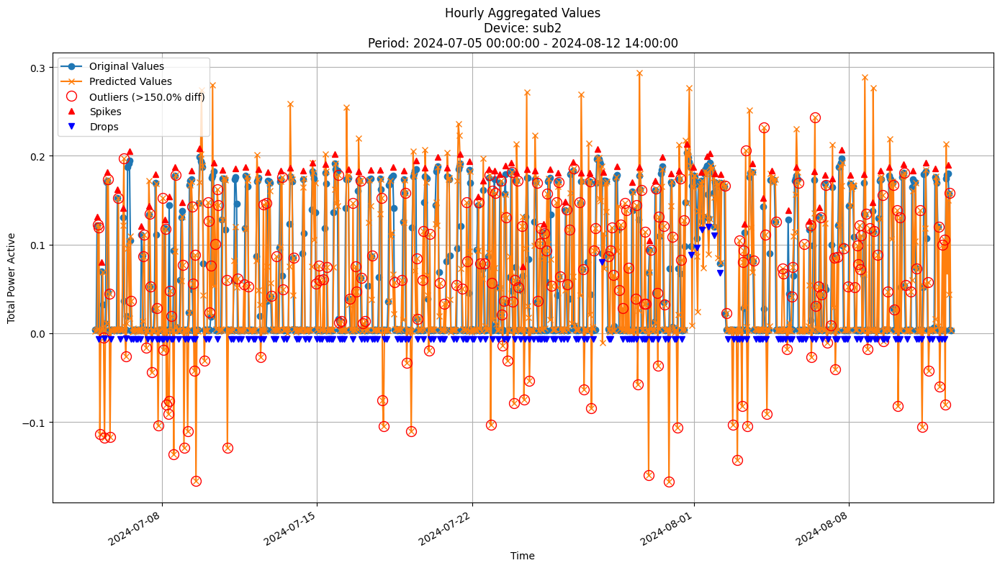


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0671
MAE: 0.0432
MAPE: 497.2030%

Directional Metrics:
Directional Accuracy: 53.1317%
First-Diff Correlation: 0.1651

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3684
  Recall: 0.0729
  F1 Score: 0.1217
Drops:
  Precision: 0.1579
  Recall: 0.0161
  F1 Score: 0.0293

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7895
  Recall: 0.1562
  F1 Score: 0.2609
Drops:
  Precision: 0.6842
  Recall: 0.0699
  F1 Score: 0.1268


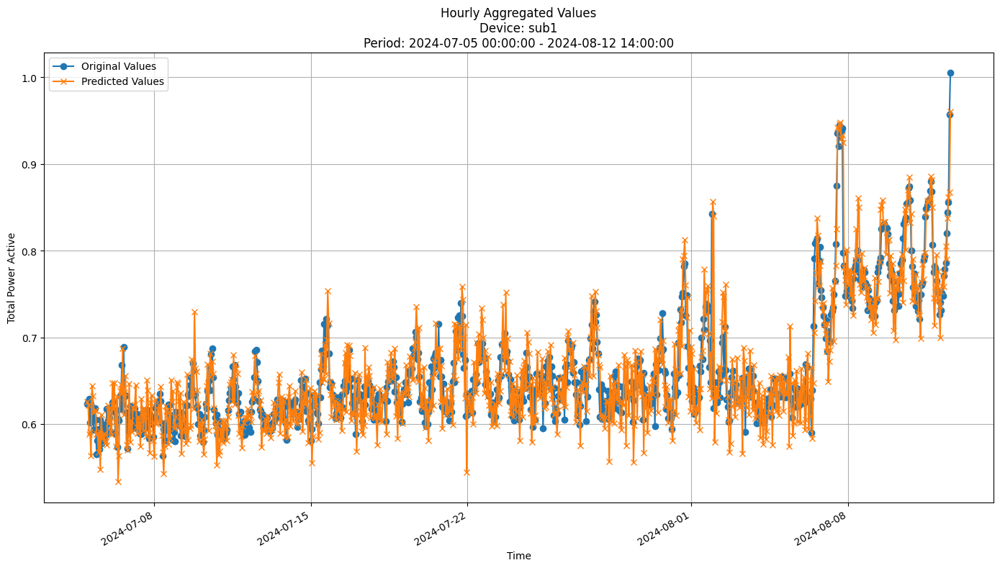


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0333
MAE: 0.0249
MAPE: 3.7916%

Directional Metrics:
Directional Accuracy: 44.4924%
First-Diff Correlation: -0.2103

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


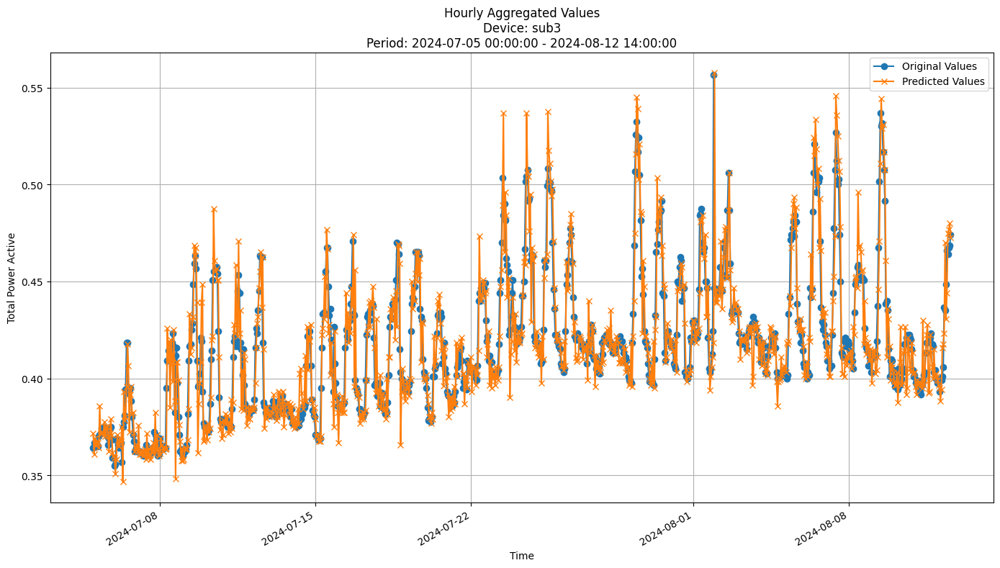


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0147
MAE: 0.0095
MAPE: 2.2260%

Directional Metrics:
Directional Accuracy: 50.1080%
First-Diff Correlation: 0.1242

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [41]:
join_periods = [-2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [42]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT

arf_params = {
    'n_models': 5, 
    'max_features': 0.5, 
    'max_depth': 30, 
    'aggregation_method': 'mean', 
    'disable_weighted_vote': True, 
    # 'drift_detector': None, 
    # 'warning_detector': None, 
    'eagerness': 0, 
    'tau': 0.05, 
    'delta': 0.05, 
    'grace_period': 96, 
    'grace_period_depth': 0, 
    'bin_type': 'mean', 
    'split_criterion': 'vr_rel'}

# {'depth': 30, 
#                'grace_period': 96, 
#                'grace_period_depth': 0, 
#                'split_confidence': 0.1, 
#                'max_feature': 0.7, 
#                'tie_threshold': 0.05, 
#                'bin_type': 'adaptive', 
#                'max_bins': 16, 
#                'split_criterion': 'vr_rel'}

# arf_params = {
#     "n_models": 20,
#     "aggregation_method": "mean",
#     "grace_period": 0,  # by default works for all leaves
#     "max_depth": 100,
#     "delta": 0.1,  # split confidence
#     "tau": 0.01,  # break ties
#     "seed": 42,
#     "max_features": 0.7,  # maximum feature ratio for each model
# }

In [ ]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 21.708168 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0640
	MAE: 0.0446
	MAPE: 525.6594%

Directional Metrics:
	Directional Accuracy: 53.5022%
	First-Diff Correlation: 0.1614

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1856
		Recall: 0.2500
		F1: 0.2130
	Drops:
		Precision: 0.2604
		Recall: 0.1880
		F1: 0.2183

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6289
		Recall: 0.8472
		F1: 0.7219
	Drops:
		Precision: 0.7292
		Recall: 0.5263
		F1: 0.6114
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 26.181847 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0639
	MAE: 0.0430
	MAPE: 531.6649%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.0852

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0256
		Recall: 0.0417
		F1: 0.0317
	Drops:
		Precision: 0.3077
		Recall: 0.2264
		F1: 0.2609

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4872
		Recall: 0.7917
		F1: 0.6032
	Drops:
		Precision: 0.7436
		Recall: 0.5472
		F1: 0.6304
--------------------------------------------------
Da

#### Results

In [44]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0570 ± 0.0015
	MAE: 0.0359 ± 0.0008
	MAPE: 492.8175% ± 18.5449%

	Directional Metrics:
		Directional Accuracy: 55.8160% ± 0.7414%
		First-Diff Correlation: 0.1605 ± 0.0168

	Immediate Detection (delta=0):
		Spike Precision: 0.2263 ± 0.0213
		Spike Recall: 0.3409 ± 0.0438
		Spike F1: 0.2719 ± 0.0293
		Drop Precision: 0.2379 ± 0.0279
		Drop Recall: 0.1779 ± 0.0235
		Drop F1: 0.2036 ± 0.0256

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5945 ± 0.0095
		Spike Recall: 0.8931 ± 0.0453
		Spike F1: 0.7136 ± 0.0213
		Drop Precision: 0.7077 ± 0.0023
		Drop Recall: 0.5284 ± 0.0064
		Drop F1: 0.6050 ± 0.0033
Daily Metrics:
	RMSE: 0.2453 ± 0.0544
	MAE: 0.1951 ± 0.0378
	MAPE: 21.7095% ± 4.6864%

	Directional Metrics:
		Directional Accuracy: 75.3535% ± 13.5354%
		First-Diff Correlation: 0.7613 ± 0.0730

	Immediate Detection (delta=0):
		S

#### Training plots

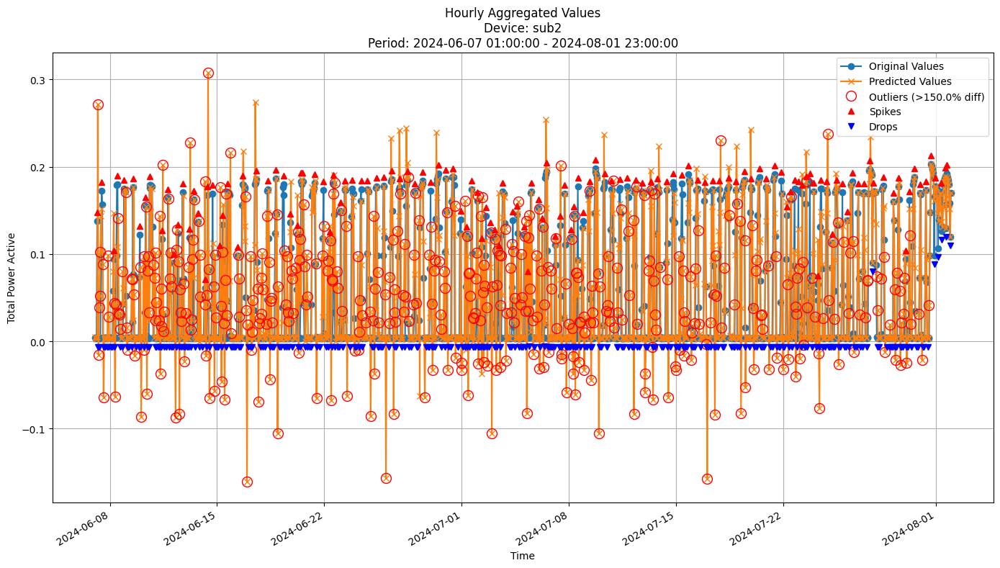


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0585
MAE: 0.0366
MAPE: 511.3624%

Directional Metrics:
Directional Accuracy: 56.5574%
First-Diff Correlation: 0.1773

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1481
  Recall: 0.0292
  F1 Score: 0.0488
Drops:
  Precision: 0.1538
  Recall: 0.0148
  F1 Score: 0.0269

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7407
  Recall: 0.1460
  F1 Score: 0.2439
Drops:
  Precision: 0.5000
  Recall: 0.0480
  F1 Score: 0.0875


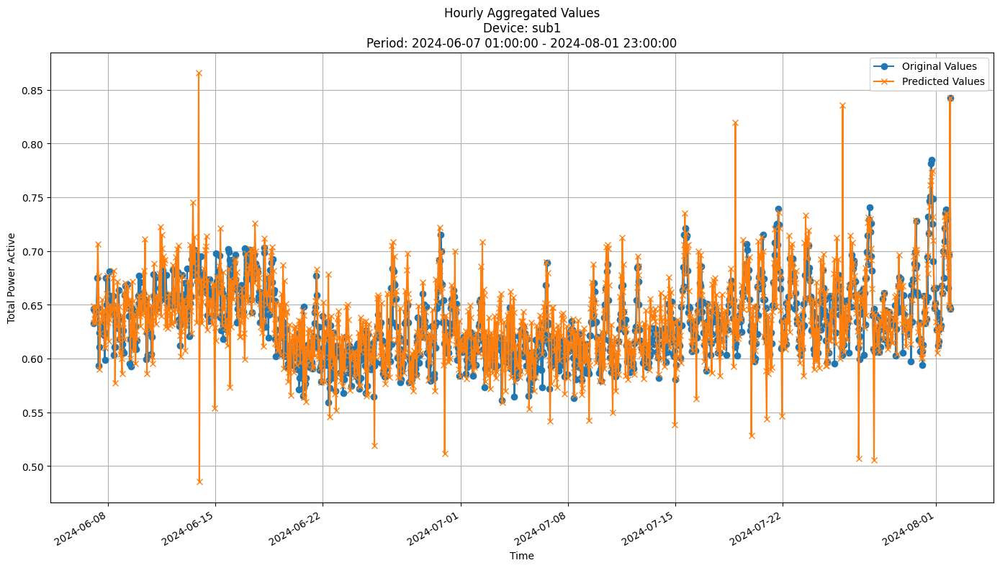


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0311
MAE: 0.0225
MAPE: 3.5733%

Directional Metrics:
Directional Accuracy: 40.9091%
First-Diff Correlation: -0.1657

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


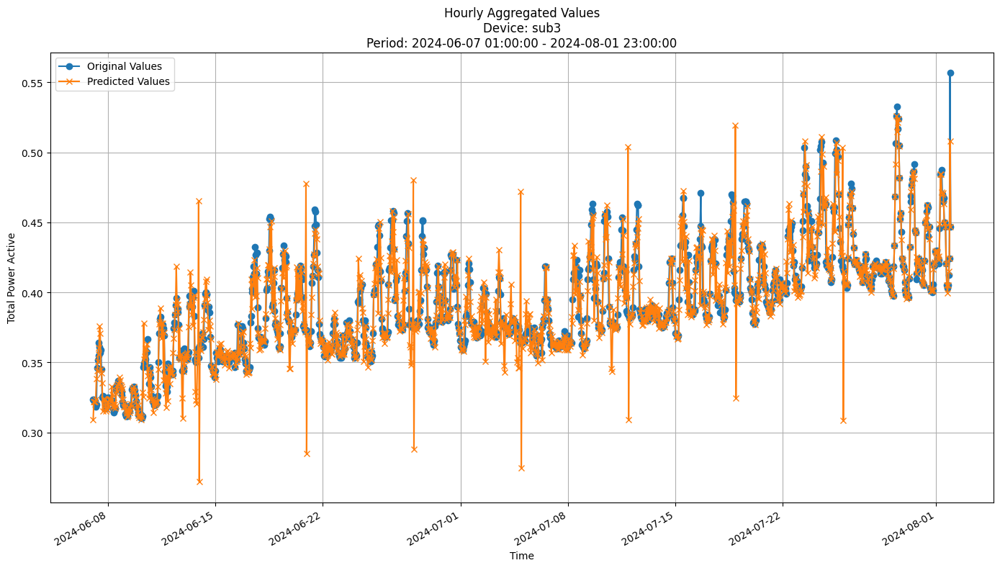


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0153
MAE: 0.0083
MAPE: 2.0862%

Directional Metrics:
Directional Accuracy: 54.9180%
First-Diff Correlation: 0.2016

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [45]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

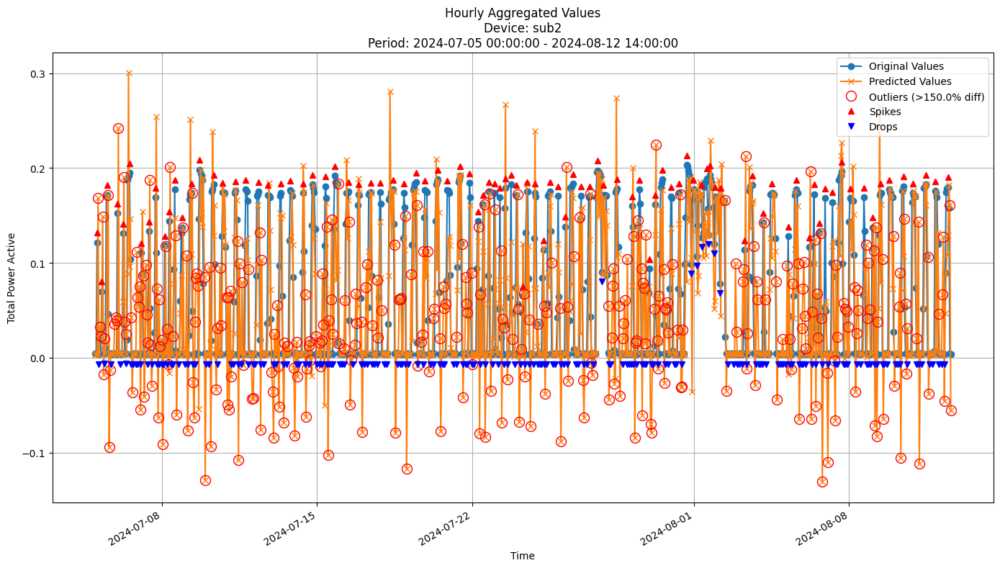


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0640
MAE: 0.0442
MAPE: 527.3114%

Directional Metrics:
Directional Accuracy: 52.6998%
First-Diff Correlation: 0.1418

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.3333
  Recall: 0.0054
  F1 Score: 0.0106

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7500
  Recall: 0.0312
  F1 Score: 0.0600
Drops:
  Precision: 1.0000
  Recall: 0.0161
  F1 Score: 0.0317


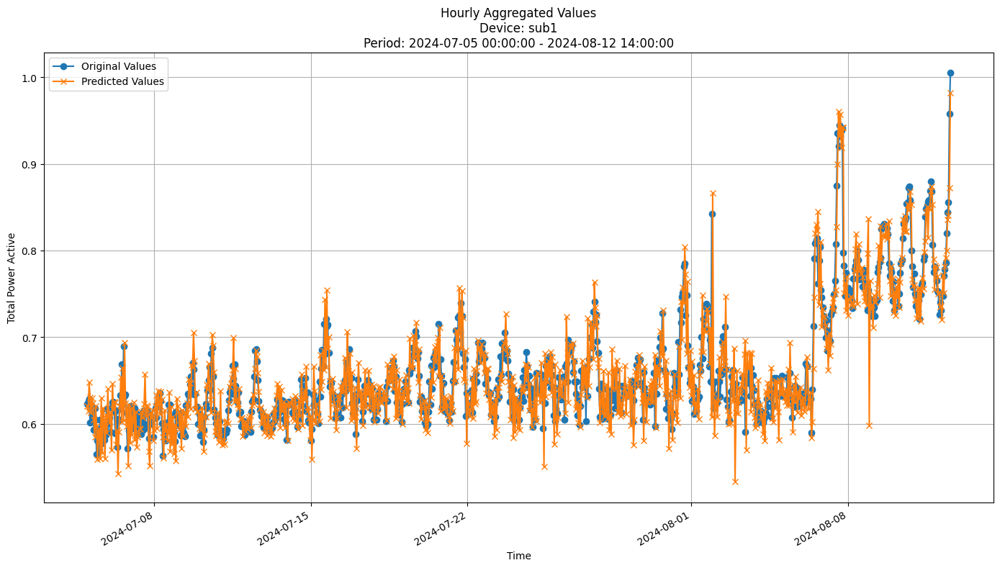


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0310
MAE: 0.0229
MAPE: 3.4811%

Directional Metrics:
Directional Accuracy: 38.9849%
First-Diff Correlation: -0.2931

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


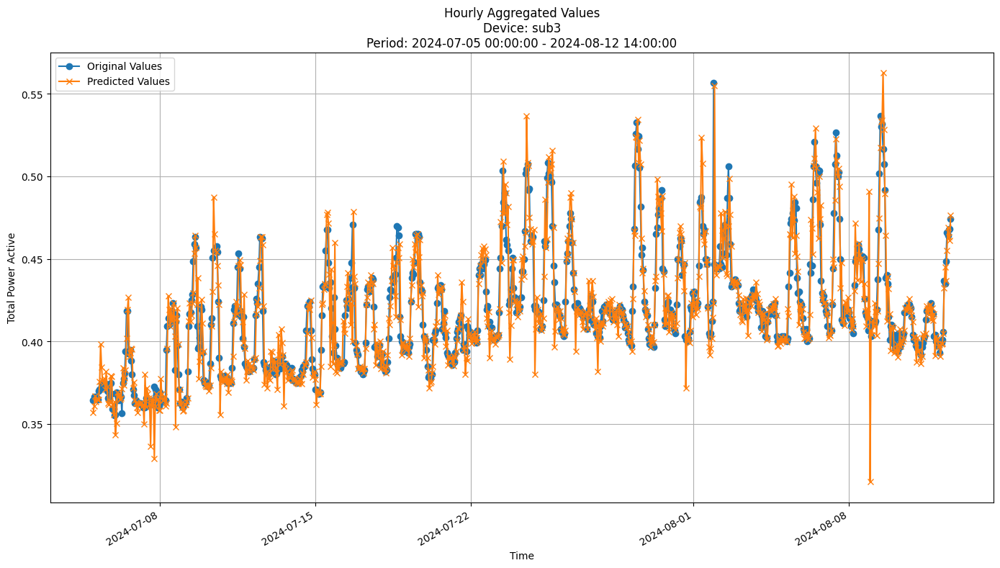


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0146
MAE: 0.0089
MAPE: 2.0759%

Directional Metrics:
Directional Accuracy: 51.6199%
First-Diff Correlation: 0.1540

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [46]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [47]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

incb = IncubationBoost

incb_params = {
    'length': 40, 
    'learning_rate': 0.5, 
    'depth': 10, 
    'grace_period': 0, 
    'grace_period_depth': 1, 
    'split_confidence': 0.05, 
    'max_feature': 1.0, 
    'tie_threshold': 0.01, 
    'bin_type': 'adaptive', 
    'max_bins': 16, 
    'split_criterion': 'vr_rel', 
    'verbose': False}


In [ ]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.374146 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1446
	MAE: 0.0928
	MAPE: 1293.9054%

Directional Metrics:
	Directional Accuracy: 42.7720%
	First-Diff Correlation: 0.0239

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1176
		Recall: 0.1111
		F1: 0.1143
	Drops:
		Precision: 0.0563
		Recall: 0.0301
		F1: 0.0392

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6912
		Recall: 0.6528
		F1: 0.6714
	Drops:
		Precision: 0.6338
		Recall: 0.3383
		F1: 0.4412
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.442627 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1405
	MAE: 0.0879
	MAPE: 1245.3638%

Directional Metrics:
	Directional Accuracy: 46.0630%
	First-Diff Correlation: 0.0976

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.1250
		F1: 0.1111
	Drops:
		Precision: 0.0645
		Recall: 0.0377
		F1: 0.0476

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6333
		Recall: 0.7917
		F1: 0.7037
	Drops:
		Precision: 0.6452
		Recall: 0.3774
		F1: 0.4762
--------------------------------------------------
Da

#### Results

In [49]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1399 ± 0.0018
	MAE: 0.0900 ± 0.0014
	MAPE: 1539.8579% ± 74.5285%

	Directional Metrics:
		Directional Accuracy: 44.1093% ± 0.5176%
		First-Diff Correlation: 0.0942 ± 0.0247

	Immediate Detection (delta=0):
		Spike Precision: 0.1059 ± 0.0118
		Spike Recall: 0.1195 ± 0.0036
		Spike F1: 0.1117 ± 0.0051
		Drop Precision: 0.0952 ± 0.0095
		Drop Recall: 0.0551 ± 0.0111
		Drop F1: 0.0696 ± 0.0115

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6390 ± 0.0743
		Spike Recall: 0.7207 ± 0.0178
		Spike F1: 0.6740 ± 0.0340
		Drop Precision: 0.7337 ± 0.0337
		Drop Recall: 0.4221 ± 0.0632
		Drop F1: 0.5346 ± 0.0600
Daily Metrics:
	RMSE: 0.1992 ± 0.0002
	MAE: 0.1839 ± 0.0015
	MAPE: 18.7748% ± 1.2739%

	Directional Metrics:
		Directional Accuracy: 93.5690% ± 0.9764%
		First-Diff Correlation: 0.9562 ± 0.0101

	Immediate Detection (delta=0):
		S

#### Train plots

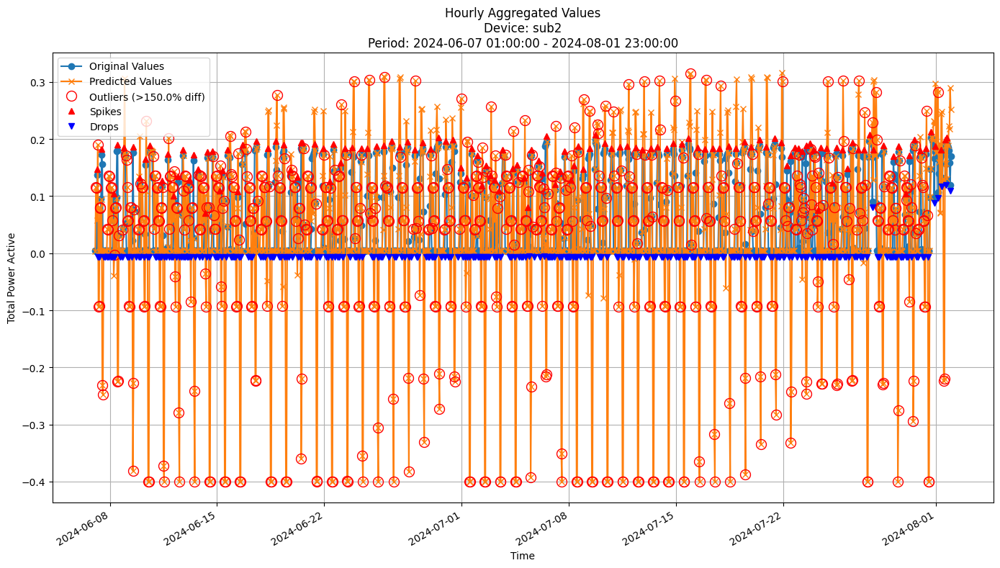


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1418
MAE: 0.0914
MAPE: 1465.3294%

Directional Metrics:
Directional Accuracy: 43.5917%
First-Diff Correlation: 0.0695

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0526
  Recall: 0.0146
  F1 Score: 0.0229
Drops:
  Precision: 0.1316
  Recall: 0.0185
  F1 Score: 0.0324

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7368
  Recall: 0.2044
  F1 Score: 0.3200
Drops:
  Precision: 0.7632
  Recall: 0.1070
  F1 Score: 0.1877


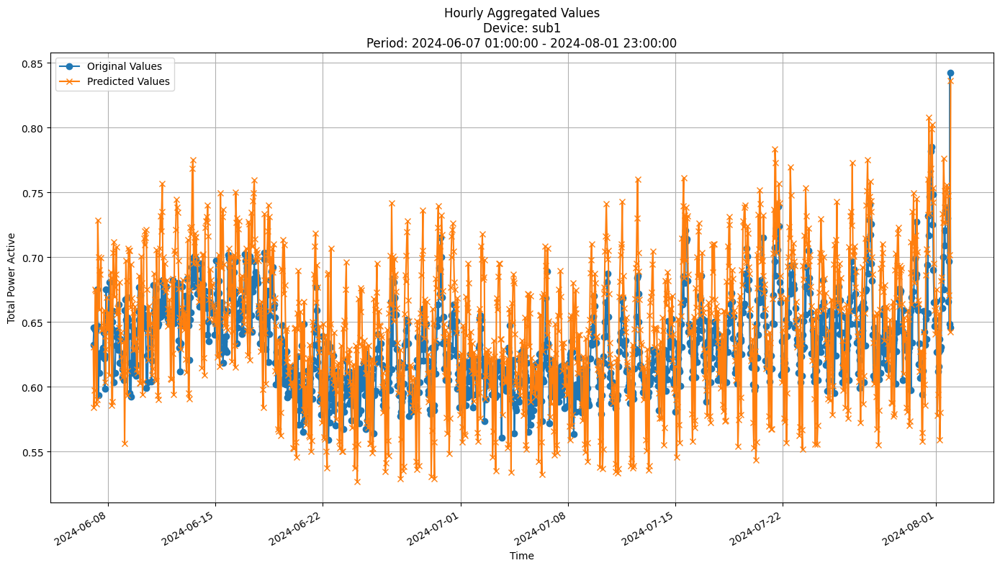


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0465
MAE: 0.0379
MAPE: 6.0239%

Directional Metrics:
Directional Accuracy: 38.2265%
First-Diff Correlation: -0.2674

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


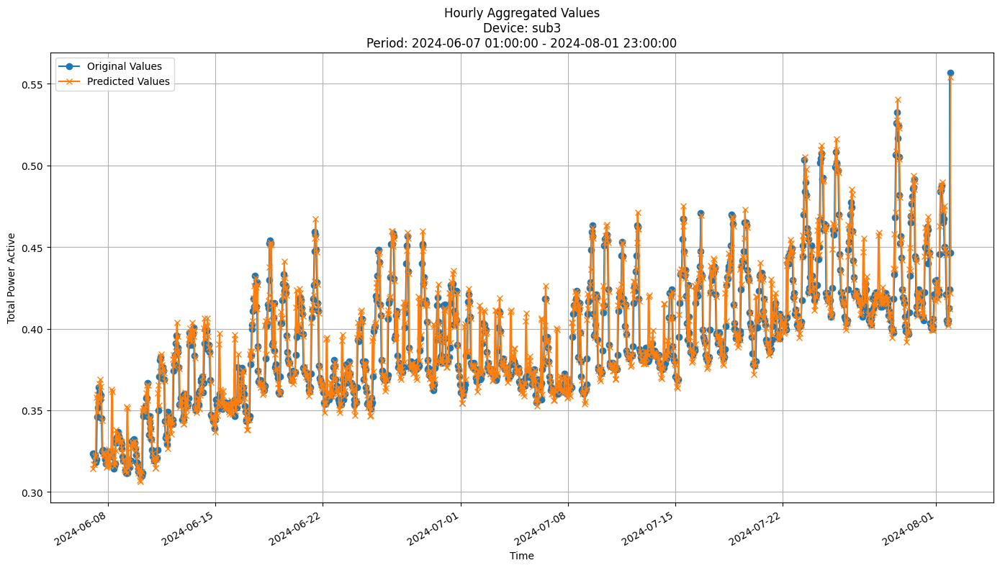


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0138
MAE: 0.0083
MAPE: 2.1163%

Directional Metrics:
Directional Accuracy: 51.2668%
First-Diff Correlation: 0.1236

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [50]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

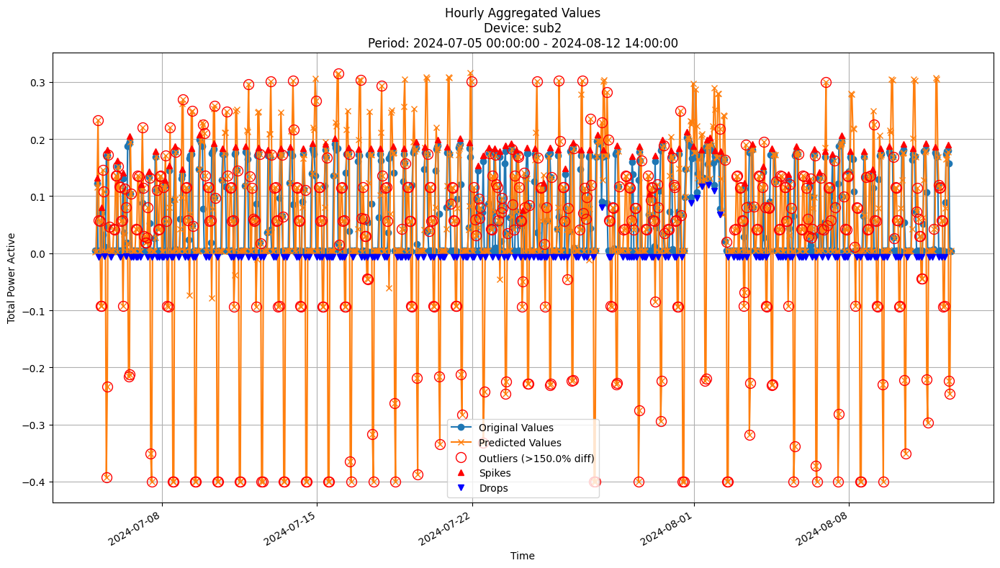


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1435
MAE: 0.0914
MAPE: 1280.5526%

Directional Metrics:
Directional Accuracy: 43.7365%
First-Diff Correlation: 0.0430

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0370
  Recall: 0.0104
  F1 Score: 0.0163
Drops:
  Precision: 0.1111
  Recall: 0.0161
  F1 Score: 0.0282

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7407
  Recall: 0.2083
  F1 Score: 0.3252
Drops:
  Precision: 0.7407
  Recall: 0.1075
  F1 Score: 0.1878


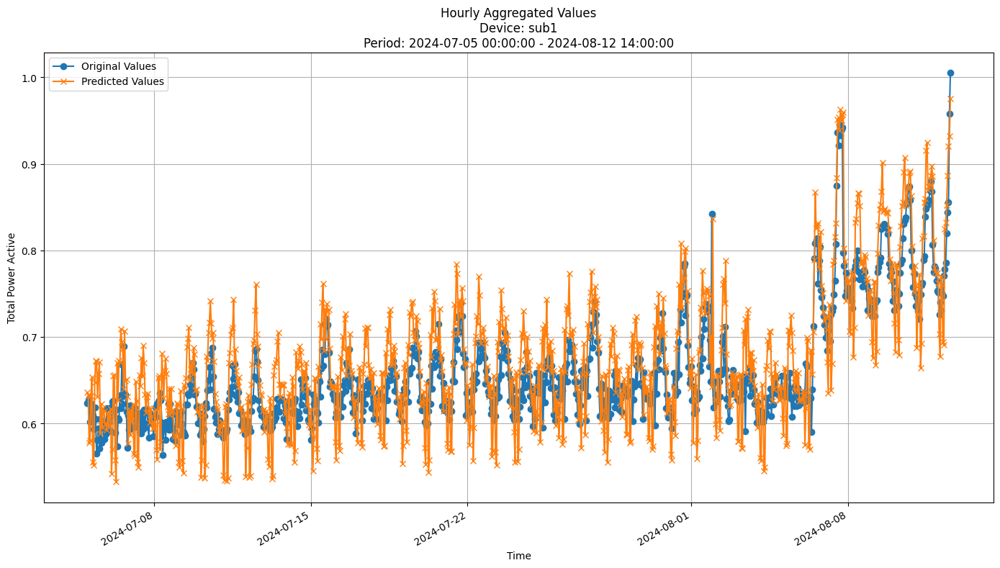


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0459
MAE: 0.0373
MAPE: 5.7299%

Directional Metrics:
Directional Accuracy: 40.0648%
First-Diff Correlation: -0.2038

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


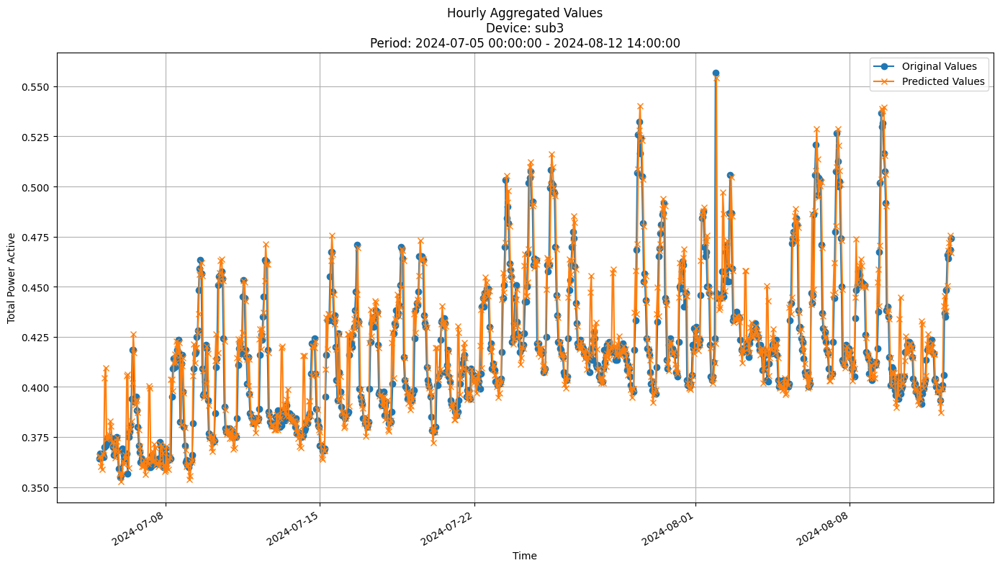


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0146
MAE: 0.0088
MAPE: 2.0742%

Directional Metrics:
Directional Accuracy: 50.6479%
First-Diff Correlation: 0.1444

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [51]:
join_periods = [-2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [ ]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.000465 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0097
	MAE: 0.0062
	MAPE: 1.5277%

Directional Metrics:
	Directional Accuracy: 45.4321%
	First-Diff Correlation: 0.1988

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-08-12 14:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-12 16:00:00+02:00 to 2024-08-26 16:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 01:00:00+02:00 to 2024-08-26 16:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-26 17:00:00+02:00 to 2024-08-29 13:00:00+02:00

-------------------------
Model's memory usage: 0.024391 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0081
	MAE: 0.0058
	MAPE: 1.4254%

Directional Metrics:
	Directional Accuracy: 51.8519%
	First-Diff Correlation: 0.2876

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 25.744919 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0111
	MAE: 0.0078
	MAPE: 1.9109%

Directional Metrics:
	Directional Accuracy: 49.8765%
	First-Diff Correlation: 0.1781

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1176
		Recall: 0.1429
		F1: 0.1290
	Drops:
		Precision: 0.1176
		Recall: 0.1176
		F1: 0.1176

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2941
		Recall: 0.3571
		F1: 0.3226
	Drops:
		Precision: 0.3529
		Recall: 0.3529
		F1: 0.3529
--------------------------------------------------
Dail

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 01:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.579697 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0123
	MAE: 0.0077
	MAPE: 1.9134%

Directional Metrics:
	Directional Accuracy: 48.6420%
	First-Diff Correlation: 0.1100

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1250
		Recall: 0.1429
		F1: 0.1333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6250
		Recall: 0.7143
		F1: 0.6667
	Drops:
		Precision: 0.4706
		Recall: 0.4706
		F1: 0.4706
--------------------------------------------------
Daily

In [54]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [55]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [56]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [57]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [58]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.028 ± 0.000,0.017 ± 0.000,1.963 ± 0.000,65.432 ± 0.000,18.836 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.029 ± 0.000,0.019 ± 0.000,2.127 ± 0.000,58.272 ± 0.000,15.840 ± 0.000,24.000 ± 0.000,56.000 ± 0.000,0.000 ± 0.000,69.231 ± 0.000
2,GBDT,0.050 ± 0.000,0.033 ± 0.000,3.623 ± 0.000,62.222 ± 0.000,14.360 ± 0.000,6.250 ± 0.000,37.500 ± 0.000,0.000 ± 0.000,35.294 ± 0.000
3,RandomForest,0.041 ± 0.000,0.028 ± 0.000,3.091 ± 0.000,63.210 ± 0.000,17.023 ± 0.000,15.385 ± 0.000,53.846 ± 0.000,7.143 ± 0.000,35.714 ± 0.000
4,HoeffdingTree,0.027 ± 0.000,0.017 ± 0.000,1.926 ± 0.000,63.951 ± 0.000,20.074 ± 0.000,8.000 ± 0.000,80.000 ± 0.000,0.000 ± 0.000,92.308 ± 0.000
5,ARF_Hoeffding,0.027 ± 0.000,0.016 ± 0.000,1.853 ± 0.000,62.716 ± 0.000,19.962 ± 0.000,8.333 ± 0.000,91.667 ± 0.000,7.692 ± 0.000,61.538 ± 0.000
6,FastODT,0.037 ± 0.000,0.025 ± 0.000,2.812 ± 0.000,57.778 ± 0.000,9.482 ± 0.000,6.250 ± 0.000,31.250 ± 0.000,5.882 ± 0.000,52.941 ± 0.000
7,ARF_FastODT,0.032 ± 0.000,0.023 ± 0.000,2.585 ± 0.000,58.272 ± 0.000,14.172 ± 0.000,0.000 ± 0.000,35.714 ± 0.000,6.897 ± 0.000,41.379 ± 0.000
8,IncubationBoost,0.045 ± 0.000,0.036 ± 0.000,4.149 ± 0.000,61.481 ± 0.000,23.092 ± 0.000,0.000 ± 0.000,44.444 ± 0.000,6.897 ± 0.000,41.379 ± 0.000




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.062 ± 0.000,0.034 ± 0.000,255.408 ± 0.000,45.185 ± 0.000,12.933 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.066 ± 0.000,0.043 ± 0.000,414.709 ± 0.000,51.852 ± 0.000,8.196 ± 0.000,9.412 ± 0.000,68.235 ± 0.000,19.298 ± 0.000,45.614 ± 0.000
2,GBDT,0.049 ± 0.000,0.035 ± 0.000,322.762 ± 0.000,58.025 ± 0.000,29.377 ± 0.000,23.256 ± 0.000,76.744 ± 0.000,22.609 ± 0.000,60.870 ± 0.000
3,RandomForest,0.051 ± 0.000,0.035 ± 0.000,309.271 ± 0.000,55.309 ± 0.000,29.173 ± 0.000,27.273 ± 0.000,81.818 ± 0.000,22.222 ± 0.000,54.701 ± 0.000
4,HoeffdingTree,0.055 ± 0.000,0.038 ± 0.000,325.314 ± 0.000,52.593 ± 0.000,16.785 ± 0.000,20.930 ± 0.000,83.721 ± 0.000,22.414 ± 0.000,55.172 ± 0.000
5,ARF_Hoeffding,0.058 ± 0.000,0.037 ± 0.000,335.182 ± 0.000,51.111 ± 0.000,13.318 ± 0.000,16.471 ± 0.000,77.647 ± 0.000,15.789 ± 0.000,56.140 ± 0.000
6,FastODT,0.076 ± 0.000,0.052 ± 0.000,660.730 ± 0.000,53.333 ± 0.000,13.903 ± 0.000,25.641 ± 0.000,70.085 ± 0.000,25.503 ± 0.000,59.060 ± 0.000
7,ARF_FastODT,0.066 ± 0.000,0.046 ± 0.000,553.262 ± 0.000,55.062 ± 0.000,17.062 ± 0.000,25.532 ± 0.000,78.723 ± 0.000,22.764 ± 0.000,61.789 ± 0.000
8,IncubationBoost,0.150 ± 0.000,0.097 ± 0.000,1120.360 ± 0.000,44.444 ± 0.000,-9.987 ± 0.000,4.396 ± 0.000,79.121 ± 0.000,3.252 ± 0.000,52.033 ± 0.000




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.010 ± 0.000,0.006 ± 0.000,1.528 ± 0.000,45.432 ± 0.000,19.885 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.008 ± 0.000,0.006 ± 0.000,1.425 ± 0.000,51.852 ± 0.000,28.765 ± 0.000,0.000 ± 0.000,50.000 ± 0.000,0.000 ± 0.000,56.250 ± 0.000
2,GBDT,0.008 ± 0.000,0.006 ± 0.000,1.444 ± 0.000,51.111 ± 0.000,26.856 ± 0.000,0.000 ± 0.000,51.852 ± 0.000,6.452 ± 0.000,45.161 ± 0.000
3,RandomForest,0.008 ± 0.000,0.006 ± 0.000,1.450 ± 0.000,50.864 ± 0.000,28.125 ± 0.000,0.000 ± 0.000,51.852 ± 0.000,6.452 ± 0.000,64.516 ± 0.000
4,HoeffdingTree,0.009 ± 0.000,0.006 ± 0.000,1.557 ± 0.000,47.160 ± 0.000,22.087 ± 0.000,0.000 ± 0.000,35.714 ± 0.000,6.250 ± 0.000,50.000 ± 0.000
5,ARF_Hoeffding,0.008 ± 0.000,0.006 ± 0.000,1.366 ± 0.000,48.889 ± 0.000,28.711 ± 0.000,7.407 ± 0.000,59.259 ± 0.000,0.000 ± 0.000,64.516 ± 0.000
6,FastODT,0.016 ± 0.000,0.010 ± 0.000,2.527 ± 0.000,48.148 ± 0.000,12.037 ± 0.000,5.556 ± 0.000,38.889 ± 0.000,5.128 ± 0.000,15.385 ± 0.000
7,ARF_FastODT,0.011 ± 0.000,0.008 ± 0.000,1.911 ± 0.000,49.877 ± 0.000,17.815 ± 0.000,12.903 ± 0.000,32.258 ± 0.000,11.765 ± 0.000,35.294 ± 0.000
8,IncubationBoost,0.012 ± 0.000,0.008 ± 0.000,1.913 ± 0.000,48.642 ± 0.000,10.999 ± 0.000,13.333 ± 0.000,66.667 ± 0.000,0.000 ± 0.000,47.059 ± 0.000


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.028 ± 0.000</td>
      <td>0.017 ± 0.000</td>
      <td>1.963 ± 0.000</td>
      <td>65.432 ± 0.000</td>
      <td>18.836 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.029 ± 0.000</td>
      <td>0.019 ± 0.000</td>
      <td>2.127 ± 0.000</td>
      <td>58.272 ± 0.000</td>
      <td>15.840 ± 0.000</td>
      <td>24.000 ± 0.000</td>
      <td>56.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>69.231 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.050 ± 0.000</td>
      <td>0.033 ± 0.000</td>
      <td>3.623 ± 0.000</td>
      <td>62.222 ± 0.000</td>
      <td>14.360 ± 0.000</td>
      <td>6.250 ± 0.000</td>
      <td>37.500 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>35.294 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.041 ± 0.000</td>
      <td>0.028 ± 0.000</td>
      <td>3.091 ± 0.000</td>
      <td>63.210 ± 0.000</td>
      <td>17.023 ± 0.000</td>
      <td>15.385 ± 0.000</td>
      <td>53.846 ± 0.000</td>
      <td>7.143 ± 0.000</td>
      <td>35.714 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.027 ± 0.000</td>
      <td>0.017 ± 0.000</td>
      <td>1.926 ± 0.000</td>
      <td>63.951 ± 0.000</td>
      <td>20.074 ± 0.000</td>
      <td>8.000 ± 0.000</td>
      <td>80.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>92.308 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.027 ± 0.000</td>
      <td>0.016 ± 0.000</td>
      <td>1.853 ± 0.000</td>
      <td>62.716 ± 0.000</td>
      <td>19.962 ± 0.000</td>
      <td>8.333 ± 0.000</td>
      <td>91.667 ± 0.000</td>
      <td>7.692 ± 0.000</td>
      <td>61.538 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.039 ± 0.000</td>
      <td>0.027 ± 0.000</td>
      <td>3.078 ± 0.000</td>
      <td>58.272 ± 0.000</td>
      <td>11.352 ± 0.000</td>
      <td>6.667 ± 0.000</td>
      <td>40.000 ± 0.000</td>
      <td>12.121 ± 0.000</td>
      <td>42.424 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.032 ± 0.000</td>
      <td>0.022 ± 0.000</td>
      <td>2.501 ± 0.000</td>
      <td>60.000 ± 0.000</td>
      <td>14.285 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>44.444 ± 0.000</td>
      <td>6.897 ± 0.000</td>
      <td>55.172 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.045 ± 0.000</td>
      <td>0.036 ± 0.000</td>
      <td>4.149 ± 0.000</td>
      <td>61.481 ± 0.000</td>
      <td>23.092 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>44.444 ± 0.000</td>
      <td>6.897 ± 0.000</td>
      <td>41.379 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.062 ± 0.000</td>
      <td>0.034 ± 0.000</td>
      <td>255.408 ± 0.000</td>
      <td>45.185 ± 0.000</td>
      <td>12.933 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.066 ± 0.000</td>
      <td>0.043 ± 0.000</td>
      <td>414.709 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>8.196 ± 0.000</td>
      <td>9.412 ± 0.000</td>
      <td>68.235 ± 0.000</td>
      <td>19.298 ± 0.000</td>
      <td>45.614 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.049 ± 0.000</td>
      <td>0.035 ± 0.000</td>
      <td>322.762 ± 0.000</td>
      <td>58.025 ± 0.000</td>
      <td>29.377 ± 0.000</td>
      <td>23.256 ± 0.000</td>
      <td>76.744 ± 0.000</td>
      <td>22.609 ± 0.000</td>
      <td>60.870 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.051 ± 0.000</td>
      <td>0.035 ± 0.000</td>
      <td>309.271 ± 0.000</td>
      <td>55.309 ± 0.000</td>
      <td>29.173 ± 0.000</td>
      <td>27.273 ± 0.000</td>
      <td>81.818 ± 0.000</td>
      <td>22.222 ± 0.000</td>
      <td>54.701 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.055 ± 0.000</td>
      <td>0.038 ± 0.000</td>
      <td>325.314 ± 0.000</td>
      <td>52.593 ± 0.000</td>
      <td>16.785 ± 0.000</td>
      <td>20.930 ± 0.000</td>
      <td>83.721 ± 0.000</td>
      <td>22.414 ± 0.000</td>
      <td>55.172 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.058 ± 0.000</td>
      <td>0.037 ± 0.000</td>
      <td>335.182 ± 0.000</td>
      <td>51.111 ± 0.000</td>
      <td>13.318 ± 0.000</td>
      <td>16.471 ± 0.000</td>
      <td>77.647 ± 0.000</td>
      <td>15.789 ± 0.000</td>
      <td>56.140 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.075 ± 0.000</td>
      <td>0.049 ± 0.000</td>
      <td>600.479 ± 0.000</td>
      <td>53.333 ± 0.000</td>
      <td>13.384 ± 0.000</td>
      <td>15.385 ± 0.000</td>
      <td>63.248 ± 0.000</td>
      <td>19.048 ± 0.000</td>
      <td>57.143 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.072 ± 0.000</td>
      <td>0.048 ± 0.000</td>
      <td>591.106 ± 0.000</td>
      <td>55.062 ± 0.000</td>
      <td>15.226 ± 0.000</td>
      <td>19.469 ± 0.000</td>
      <td>70.796 ± 0.000</td>
      <td>23.776 ± 0.000</td>
      <td>61.538 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.150 ± 0.000</td>
      <td>0.097 ± 0.000</td>
      <td>1120.360 ± 0.000</td>
      <td>44.444 ± 0.000</td>
      <td>-9.987 ± 0.000</td>
      <td>4.396 ± 0.000</td>
      <td>79.121 ± 0.000</td>
      <td>3.252 ± 0.000</td>
      <td>52.033 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.010 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.528 ± 0.000</td>
      <td>45.432 ± 0.000</td>
      <td>19.885 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.425 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>28.765 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>50.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>56.250 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.444 ± 0.000</td>
      <td>51.111 ± 0.000</td>
      <td>26.856 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>6.452 ± 0.000</td>
      <td>45.161 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.450 ± 0.000</td>
      <td>50.864 ± 0.000</td>
      <td>28.125 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>51.852 ± 0.000</td>
      <td>6.452 ± 0.000</td>
      <td>64.516 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.009 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.557 ± 0.000</td>
      <td>47.160 ± 0.000</td>
      <td>22.087 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>35.714 ± 0.000</td>
      <td>6.250 ± 0.000</td>
      <td>50.000 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.008 ± 0.000</td>
      <td>0.006 ± 0.000</td>
      <td>1.366 ± 0.000</td>
      <td>48.889 ± 0.000</td>
      <td>28.711 ± 0.000</td>
      <td>7.407 ± 0.000</td>
      <td>59.259 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>64.516 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.013 ± 0.000</td>
      <td>0.008 ± 0.000</td>
      <td>2.038 ± 0.000</td>
      <td>47.901 ± 0.000</td>
      <td>13.609 ± 0.000</td>
      <td>6.452 ± 0.000</td>
      <td>38.710 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>40.000 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.010 ± 0.000</td>
      <td>0.007 ± 0.000</td>
      <td>1.823 ± 0.000</td>
      <td>49.630 ± 0.000</td>
      <td>17.763 ± 0.000</td>
      <td>13.333 ± 0.000</td>
      <td>33.333 ± 0.000</td>
      <td>5.882 ± 0.000</td>
      <td>29.412 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.012 ± 0.000</td>
      <td>0.008 ± 0.000</td>
      <td>1.913 ± 0.000</td>
      <td>48.642 ± 0.000</td>
      <td>10.999 ± 0.000</td>
      <td>13.333 ± 0.000</td>
      <td>66.667 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>47.059 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

## Validation results

In [59]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.025 ± 0.000,0.018 ± 0.001,2.626 ± 0.268,41.266 ± 9.522,-25.975 ± 29.052,0.000 ± 0.000,99.275 ± 0.725,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.025 ± 0.001,0.019 ± 0.001,2.746 ± 0.327,42.341 ± 6.872,-19.069 ± 24.319,2.500 ± 2.500,26.250 ± 26.250,1.250 ± 1.250,26.250 ± 26.250
2,GBDT,0.026 ± 0.001,0.019 ± 0.001,2.790 ± 0.070,42.080 ± 9.889,-24.202 ± 28.435,2.740 ± 2.740,73.059 ± 6.393,0.000 ± 0.000,36.986 ± 36.986
3,RandomForest,0.025 ± 0.000,0.018 ± 0.000,2.696 ± 0.158,41.888 ± 8.505,-24.826 ± 28.797,2.778 ± 2.778,87.500 ± 12.500,0.000 ± 0.000,40.278 ± 40.278
4,HoeffdingTree,0.024 ± 0.001,0.017 ± 0.001,2.576 ± 0.316,39.616 ± 8.022,-26.045 ± 28.695,2.941 ± 2.941,92.647 ± 7.353,0.000 ± 0.000,91.176 ± 8.824
5,ARF_Hoeffding,0.024 ± 0.001,0.017 ± 0.001,2.565 ± 0.329,41.531 ± 10.831,-24.440 ± 29.934,0.000 ± 0.000,92.857 ± 7.143,0.000 ± 0.000,41.429 ± 41.429
6,FastODT,0.034 ± 0.001,0.025 ± 0.001,3.744 ± 0.105,46.896 ± 5.466,-14.480 ± 16.481,1.980 ± 1.980,36.469 ± 3.135,0.990 ± 0.990,35.078 ± 6.506
7,ARF_FastODT,0.031 ± 0.000,0.023 ± 0.001,3.357 ± 0.276,43.096 ± 9.266,-20.567 ± 24.507,4.854 ± 4.854,49.272 ± 0.728,0.000 ± 0.000,29.126 ± 29.126
8,IncubationBoost,0.046 ± 0.001,0.037 ± 0.001,5.536 ± 0.431,43.841 ± 8.521,-12.924 ± 18.574,1.235 ± 1.235,21.111 ± 1.111,2.469 ± 2.469,24.815 ± 4.815




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.058 ± 0.002,0.031 ± 0.002,243.771 ± 15.178,41.167 ± 1.009,10.417 ± 0.178,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,99.811 ± 0.189
1,BL_Mean,0.062 ± 0.003,0.041 ± 0.003,448.769 ± 20.835,52.070 ± 1.283,8.143 ± 0.778,10.122 ± 1.959,75.661 ± 2.191,20.304 ± 0.209,53.871 ± 2.589
2,GBDT,0.048 ± 0.001,0.034 ± 0.001,384.163 ± 31.106,57.971 ± 0.296,25.774 ± 2.463,32.581 ± 2.793,88.218 ± 1.143,26.551 ± 2.396,56.833 ± 3.693
3,RandomForest,0.049 ± 0.000,0.035 ± 0.001,386.271 ± 58.651,54.268 ± 0.725,25.920 ± 4.985,35.813 ± 1.771,87.748 ± 5.869,21.842 ± 1.842,58.358 ± 2.168
4,HoeffdingTree,0.053 ± 0.002,0.035 ± 0.002,293.368 ± 35.613,45.722 ± 2.415,13.247 ± 0.649,19.577 ± 6.811,94.031 ± 0.414,15.248 ± 0.542,53.122 ± 2.141
5,ARF_Hoeffding,0.054 ± 0.002,0.035 ± 0.002,328.894 ± 12.039,54.098 ± 1.342,11.165 ± 0.645,10.164 ± 2.164,85.836 ± 1.836,23.189 ± 0.112,60.207 ± 3.896
6,FastODT,0.068 ± 0.002,0.044 ± 0.001,510.821 ± 30.274,51.954 ± 2.741,13.397 ± 6.582,18.983 ± 3.598,68.255 ± 0.562,18.098 ± 1.256,60.119 ± 1.171
7,ARF_FastODT,0.064 ± 0.000,0.044 ± 0.001,528.662 ± 3.003,52.145 ± 1.357,12.330 ± 3.810,12.238 ± 9.064,66.253 ± 5.936,23.961 ± 2.126,62.089 ± 0.954
8,IncubationBoost,0.143 ± 0.002,0.090 ± 0.002,1269.635 ± 24.271,44.417 ± 1.646,6.072 ± 3.686,11.270 ± 0.159,68.757 ± 1.614,4.342 ± 0.420,45.868 ± 1.751




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.012 ± 0.001,0.007 ± 0.000,1.650 ± 0.055,50.953 ± 0.165,24.979 ± 13.119,0.000 ± 0.000,98.936 ± 1.064,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.011 ± 0.001,0.007 ± 0.000,1.540 ± 0.057,52.118 ± 0.937,27.484 ± 9.844,8.696 ± 8.696,79.766 ± 2.843,20.669 ± 7.903,61.246 ± 10.182
2,GBDT,0.015 ± 0.002,0.011 ± 0.003,2.545 ± 0.693,49.059 ± 2.208,17.388 ± 5.913,10.370 ± 2.963,51.852 ± 14.815,7.919 ± 0.776,35.248 ± 0.466
3,RandomForest,0.014 ± 0.001,0.009 ± 0.002,2.171 ± 0.386,51.469 ± 0.500,23.192 ± 10.001,12.549 ± 0.784,62.745 ± 3.922,12.077 ± 0.966,35.024 ± 12.802
4,HoeffdingTree,0.011 ± 0.001,0.007 ± 0.000,1.631 ± 0.032,51.272 ± 0.303,25.864 ± 12.602,6.522 ± 6.522,78.623 ± 4.710,0.000 ± 0.000,60.556 ± 0.982
5,ARF_Hoeffding,0.011 ± 0.001,0.007 ± 0.000,1.498 ± 0.028,51.719 ± 0.144,26.821 ± 11.169,6.522 ± 6.522,89.130 ± 10.870,2.128 ± 2.128,58.429 ± 3.110
6,FastODT,0.014 ± 0.001,0.010 ± 0.000,2.213 ± 0.028,50.282 ± 0.505,19.613 ± 13.100,23.137 ± 3.529,75.294 ± 4.706,15.686 ± 7.843,39.216 ± 3.922
7,ARF_FastODT,0.014 ± 0.000,0.009 ± 0.000,2.027 ± 0.108,51.692 ± 0.276,18.510 ± 6.441,12.132 ± 0.368,48.162 ± 10.662,15.538 ± 7.991,44.506 ± 14.317
8,IncubationBoost,0.015 ± 0.000,0.009 ± 0.000,2.070 ± 0.009,50.288 ± 0.681,19.102 ± 9.147,8.333 ± 8.333,61.806 ± 17.361,6.122 ± 6.122,43.179 ± 22.127


### By-period validation results

In [60]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [61]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,31.744,35.469,32.191,33.383,31.595,30.700,41.431,33.830,35.320,33.962556
Period 2,50.787,49.213,51.969,50.394,47.638,52.362,52.362,52.362,52.362,51.049889



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,19.043,13.744,19.778,17.011,16.043,21.662,10.931,18.532,17.042,17.087



Device: sub2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,42.176,53.353,57.675,54.993,48.137,55.440,54.694,53.502,42.772,51.415778
Period 2,40.157,50.787,58.268,53.543,43.307,52.756,49.213,50.787,46.063,49.431222


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,51.118,53.055,51.267,50.969,50.969,51.863,49.776,51.416,50.969,51.266889
Period 2,50.787,51.181,46.850,51.969,51.575,51.575,50.787,51.969,49.606,50.699889



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.331,-1.874,-4.417,1.000,0.606,-0.288,1.011,0.553,-1.363,-0.567


#### MAPE (lower is better)

In [62]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,2.894,3.072,2.860,2.854,2.892,2.893,3.849,3.633,5.967,3.434889
Period 2,2.358,2.419,2.720,2.538,2.260,2.236,3.640,3.081,5.105,2.928556



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.536,-0.653,-0.140,-0.316,-0.632,-0.657,-0.209,-0.552,-0.862,-0.506



Device: sub2 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,258.949,469.604,353.056,327.620,328.982,340.933,480.547,525.659,1293.905,486.583889
Period 2,228.593,427.934,415.269,444.922,257.755,316.855,541.096,531.665,1245.364,489.939222


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.704,1.597,1.852,1.785,1.663,1.526,2.241,2.135,2.079,1.842444
Period 2,1.595,1.483,3.238,2.557,1.600,1.470,2.185,1.919,2.061,2.012000



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.109,-0.114,1.386,0.772,-0.063,-0.056,-0.056,-0.216,-0.018,0.170


#### RMSE (lower is better)

In [63]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.025,0.027,0.025,0.025,0.025,0.025,0.032,0.031,0.046,0.029000
Period 2,0.024,0.024,0.027,0.026,0.024,0.023,0.035,0.031,0.045,0.028778



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,-0.003,0.002,0.001,-0.001,-0.002,0.003,0.000,-0.001,-0.000



Device: sub2 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.060,0.065,0.049,0.049,0.055,0.056,0.066,0.064,0.145,0.067667
Period 2,0.056,0.059,0.047,0.049,0.051,0.052,0.069,0.064,0.140,0.065222


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.013,0.012,0.013,0.012,0.012,0.012,0.015,0.015,0.015,0.013222
Period 2,0.012,0.010,0.018,0.015,0.010,0.010,0.013,0.014,0.014,0.012889



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,-0.002,0.005,0.003,-0.002,-0.002,-0.002,-0.001,-0.001,-0.000
